# Pause & Find: last-seen object retrieval (Kaggle or Colab, CPU)
One fixed camera view, 8 zones, 5 objects. A pretrained encoder (DINOv2 ViT-S/14 by default, as in the proposal) embeds the registration photos and every zone crop. Cosine similarity plus one threshold decides whether an object is seen in a zone. **Nothing is trained.**

**Protocol, enforced in code:**
1. **Part C uses Session 1 only.** It picks the threshold and settings, then writes `frozen_config.json`.
2. **Part D refuses to run without that file.** It fixes the Session 2 query list on disk before any Session 2 photo goes through the encoder.
3. **Answers only use frames at or before the query time.** Part D includes a check that changing future frames never changes an answer.
4. **The placement log (`gt`) is read only for calibration labels (S1) and scoring (S2).** It is never an input to an answer.
5. **Rounds.** Round 1 (whole-zone DINOv2 crops) was frozen and evaluated on Session 2, and it failed. Round 2 adds new methods, again chosen on Session 1 only, and writes its own files (`*_r2.*`), so round 1's frozen config and results stay on record. Round 2 was designed *after* round 1's Session 2 results were seen, so report it as a second round. **Round 3** keeps round 2's frozen method and threshold and adds the proposal's usual-zone prior ("match × prior"); the prior was declared in the proposal but missing from rounds 1-2. Set `ROUND` in A1 (1, 2 or 3).

**Setup on Kaggle** (detected automatically):
1. **Datasets → New Dataset.** Upload the two session zips, the registration zip (`Compressed-….zip`), `placement_log_v4_corrected_with_S2.xlsx` and, if you have it, the Session 2 COCO export. **Keep the dataset Private**, because people appear in the photos. Kaggle usually unzips archives; the notebook works either way.
2. **Import this notebook** in the notebook editor (**File → Import Notebook**), then **Add Input** → your dataset.
3. **In the notebook settings:**
   * **Accelerator:** None (CPU) works. For round 2, **GPU T4** is much faster (minutes instead of about an hour the first time); the notebook uses the GPU automatically when one is on, and the runtime figures in D5 then describe the GPU.
   * **Internet: On**, needed to download DINOv2 and OWLv2 (requires a phone-verified Kaggle account).
   * **Persistence: Files only**, if offered, so `/kaggle/working/cache` survives between sessions.
4. **Run all.** **D7** draws the proposal's figures and checks H1/H2; **D8** summarises everything. Download the **`results`** folder: `report_r3.html` (open it in a browser; charts, tables and examples in one file), the charts as PNG, readable CSVs and the frozen config. The `cache` folder holds the raw files: `frozen_config.json`, `queries_S2.csv` and `s2_results.csv` (round 2: `frozen_config_r2.json`, `s2_results_r2.csv`) from the Output panel, or use **Save Version**. If you later attach a previous version's output as an input, the notebook restores those files.

**Setup on Colab:** put the same files in a Drive folder, set `DATA_ROOT` in A1, choose a CPU runtime and run all.

Embeddings are cached in `CACHE`, so re-runs are fast.

## Part A: data, timestamps, zones

In [2]:
# A1: configuration and paths. The environment (Kaggle, Colab or local) is detected automatically.
import os, sys, re, json, time, zipfile, shutil, subprocess, datetime as dt, hashlib, warnings, importlib.util
from pathlib import Path
import numpy as np, pandas as pd
from PIL import Image, ImageOps, ImageDraw, ImageFilter
import matplotlib.pyplot as plt

def _has_module(name):          # find_spec('a.b') raises if package 'a' is missing
    try: return importlib.util.find_spec(name) is not None
    except ModuleNotFoundError: return False

if os.environ.get('KAGGLE_KERNEL_RUN_TYPE') or Path('/kaggle/input').exists():
    ENV = 'kaggle'
elif _has_module('google.colab'):
    ENV = 'colab'
else:
    ENV = 'local'

if ENV == 'kaggle':
    DATA_ROOT = Path('/kaggle/input')            # attached datasets (read-only); searched recursively
    WORK = Path('/tmp/pf_work')                  # scratch space for unzipped photos (not saved)
    CACHE = Path('/kaggle/working/cache')        # saved: embeddings, frozen config, query list, results
elif ENV == 'colab':
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_ROOT = Path('/content/drive/MyDrive/CV_Project')   # <- EDIT: Drive folder with the zips + xlsx
    WORK = Path('/content/work')
    CACHE = DATA_ROOT / 'cache'                  # on Drive, so it survives sessions
else:
    DATA_ROOT = Path(os.environ.get('DATA_ROOT', '.'))
    WORK = Path(os.environ.get('WORK', './work'))
    CACHE = Path(os.environ.get('CACHE', str(DATA_ROOT / 'cache')))
IN_COLAB = ENV == 'colab'
for p in (WORK, CACHE): p.mkdir(parents=True, exist_ok=True)

if ENV == 'kaggle':   # restore a previous run's cache if its output was attached as an input
    for p in sorted(DATA_ROOT.rglob('*')):
        if p.is_file() and p.parent.name == 'cache' and p.suffix in ('.json', '.csv', '.npz') and not (CACHE / p.name).exists():
            shutil.copy2(p, CACHE / p.name); print('restored', p.name, 'from', p.parent)

ENCODER = 'dinov2_small'             # 'dinov2_small' (proposal) or 'dinov3_small' (gated: needs HF access + token)
INPUT_SIZE = 224                     # encoder input; crops are letterboxed to this, never centre-cropped
DEVICE = 'auto'                      # 'auto' = GPU if the notebook has one, else CPU; or force 'cpu' / 'cuda'.
                                     # Report timings for the device actually used (printed in B2 and D5).
SEED = 2026
ROUND = 3                            # 1 = original frozen setup (whole-zone crops); 2 = revised setup, chosen on Session 1 only
                                     # after round 1 failed on Session 2; 3 = round 2's method and threshold plus the
                                     # proposal's usual-zone prior (match x prior). See the note at the start of Part C.
def round_file(name):
    """Round-specific output file. Round 1 keeps the original names, so its frozen config and results are never overwritten."""
    stem, ext = name.rsplit('.', 1)
    return CACHE / (name if ROUND == 1 else f'{stem}_r{ROUND}.{ext}')
OBJECTS = ['Keys', 'Wallet', 'Mug', 'Phone', 'Water bottle']
REG_FOLDERS = {'keys': 'Keys', 'wallet': 'Wallet', 'mugs': 'Mug', 'mug': 'Mug', 'phone': 'Phone',
               'water_bottle': 'Water bottle', 'bottle': 'Water bottle'}

# Unzip whatever is still zipped (Kaggle normally unzips uploads; the per-object zips inside the
# registration zip may stay zipped), then index every file once.
ZIP_DIR = WORK / 'unzipped'
def zip_member_name(info):
    """Zips made on Windows/macOS often store UTF-8 names without the UTF-8 flag; Python then decodes them
    as cp437, so the narrow no-break space in the photo names turns into garbage. Undo that."""
    name = info.filename
    if not info.flag_bits & 0x800:
        try: name = name.encode('cp437').decode('utf-8')
        except (UnicodeEncodeError, UnicodeDecodeError): pass
    return name

def extract_zip(z, dest):
    tmp = dest.with_name(dest.name + '.partial')
    shutil.rmtree(tmp, ignore_errors=True); tmp.parent.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(z) as zf:
        for info in zf.infolist():
            if info.is_dir(): continue
            target = (tmp / zip_member_name(info)).resolve()
            if not str(target).startswith(str(tmp.resolve())): continue      # skip unsafe paths
            target.parent.mkdir(parents=True, exist_ok=True)
            with zf.open(info) as fsrc, open(target, 'wb') as fdst: shutil.copyfileobj(fsrc, fdst)
    tmp.rename(dest)                     # only a fully extracted zip counts as done

def extract_all_zips():
    done, todo = set(), sorted(DATA_ROOT.rglob('*.zip'))
    while todo:
        z = todo.pop(0)
        if z in done: continue
        done.add(z)
        # unique parent per zip, but keep the zip's own name as the folder name: B1 maps folder names
        # like "keys" or "mugs" to objects
        dest = ZIP_DIR / hashlib.md5(str(z).encode()).hexdigest()[:8] / z.stem
        if not dest.exists():
            try: extract_zip(z, dest)
            except zipfile.BadZipFile as e:     # never drop data silently: a broken zip stops the run
                raise RuntimeError(f'{z} is not a readable zip (corrupt or incomplete upload?). '
                                   f'Re-upload it to the dataset and run again.') from e
        todo += [n for n in sorted(dest.rglob('*.zip')) if n not in done]
extract_all_zips()

def all_files():
    seen, out = set(), []
    for root in (DATA_ROOT, ZIP_DIR):
        for p in sorted(root.rglob('*')):
            rp = p.resolve()
            if p.is_file() and rp not in seen: seen.add(rp); out.append(p)
    return out
FILES = all_files()
IMAGES = [p for p in FILES if p.suffix.lower() in ('.jpg', '.jpeg', '.png')]
xl = sorted([p for p in FILES if p.suffix == '.xlsx' and 'placement_log_v4' in p.name], key=lambda p: ('S2' not in p.name, p.name))
assert xl, (f'placement_log_v4*.xlsx not found under {DATA_ROOT}. Did you Add Input -> your dataset? '
            f'Files seen: {[str(p) for p in FILES[:20]]}')
XLSX = xl[0]
print(f'{ENV}: {len(IMAGES)} images, workbook {XLSX.name}, cache -> {CACHE}')

kaggle: 287 images, workbook placement_log_v4_corrected_with_S2.xlsx, cache -> /kaggle/working/cache


In [3]:
# A2: frame table with times from the file names (camera clock)
# Names look like IMG1_2026_11_15-00_52_29_9580<sep>am_81FED114.jpeg. The separator before am/pm is a narrow
# no-break space (U+202F); unzip tools and upload sites may turn it into "#U202f" or another character.
# Accept the real U+202F, "#U202f", URL-encoding, a space/underscore, mojibake (e.g. "â€¯"), or nothing.
NAME_RE = re.compile(r'(IMG\d+)_(\d{4})_(\d{2})_(\d{2})-(\d{1,2})_(\d{2})_(\d{2})_(\d+)(?:#U202f|%E2%80%AF|[^0-9A-Za-z]{0,8})([ap]m)_', re.I)
SESSION_DATE = {'S1': dt.date(2026, 11, 15), 'S2': dt.date(2026, 11, 16)}

def parse_name(name):
    m = NAME_RE.match(name)
    if not m: return None
    frame, Y, M, D, h, mi, s, frac, ampm = m.groups()
    hour = int(h) % 12 + (12 if ampm.lower() == 'pm' else 0)
    return frame, dt.datetime(int(Y), int(M), int(D), hour, int(mi), int(s), int(frac.ljust(6, '0')[:6]))

rows, seen_frames = [], set()
for p in IMAGES:
    parsed = parse_name(p.name)
    if parsed is None: continue
    path_l = str(p).lower()
    sess = 'S1' if 'session1' in path_l else 'S2' if 'session2' in path_l else \
           next((k for k, d in SESSION_DATE.items() if d == parsed[1].date()), None)
    if sess is None or (sess, parsed[0]) in seen_frames: continue
    assert parsed[1].date() == SESSION_DATE[sess], f'{p.name}: date does not match {sess}'
    seen_frames.add((sess, parsed[0]))
    rows.append({'session': sess, 'frame': parsed[0], 'time': parsed[1], 'path': str(p)})
if not rows:
    sample = [p.name for p in IMAGES if p.name.upper().startswith('IMG')][:10] or [p.name for p in IMAGES][:10]
    raise RuntimeError(f'No session frames matched the expected file-name pattern. {len(IMAGES)} images found; '
                       f'examples: {[ascii(n) for n in sample]}')
frames = pd.DataFrame(rows).sort_values(['session', 'time']).reset_index(drop=True)
frames['i'] = frames.groupby('session').cumcount()             # position within the session
frames['gap_s'] = frames.groupby('session')['time'].diff().dt.total_seconds()
FR = {s: g.reset_index(drop=True) for s, g in frames.groupby('session')}
for s, g in FR.items():
    print(f"{s}: {len(g)} frames, {g.time.iloc[0].time()} -> {g.time.iloc[-1].time()}, gap {g.gap_s.min():.1f}-{g.gap_s.max():.1f} s")
assert {s: len(g) for s, g in FR.items()} == {'S1': 20, 'S2': 60}, {s: len(g) for s, g in FR.items()}

S1: 20 frames, 00:52:29.958000 -> 01:02:18.181000, gap 30.0-31.9 s
S2: 60 frames, 22:16:11.657000 -> 22:46:35.680000, gap 30.0-32.0 s


In [4]:
# A3: zone polygons from the placement log (S1: "Zones" tab; S2: redrawn polygons in "S2 Notes")
import openpyxl
wb = openpyxl.load_workbook(XLSX, data_only=True)
SHEETS = {re.sub(r'\s+', ' ', n).strip().lower(): n for n in wb.sheetnames}
def get_sheet(name):
    key = name.lower()
    assert key in SHEETS, f'sheet "{name}" not found in {XLSX.name}; sheets: {wb.sheetnames}'
    return wb[SHEETS[key]]

def norm(v):                     # cell -> clean upper-case text ('' for empty)
    return re.sub(r'\s+', ' ', str(v)).strip().upper() if v is not None else ''

def zone_id(v):
    """Zone number 1-8 whether stored as 1, 1.0 or "1" (re-saving a workbook can change the type)."""
    if isinstance(v, bool): return None
    if isinstance(v, float) and v.is_integer(): v = int(v)
    if isinstance(v, str) and re.fullmatch(r'\s*\d+(\.0+)?\s*', v): v = int(float(v))
    return v if isinstance(v, int) and 1 <= v <= 8 else None

def parse_poly(text):
    return [tuple(float(v) for v in pt.split(',')) for pt in re.findall(r'\(([^)]+)\)', str(text))]

def zones_from_rows(rows_iter):
    out = {}
    for r in rows_iter:
        if len(r) < 3: continue
        z = zone_id(r[0])
        poly = parse_poly(r[2]) if z and r[2] else []
        if z and len(poly) >= 3: out[z] = {'name': str(r[1]).strip(), 'poly': poly}
    return out

ZONES = {'S1': zones_from_rows(get_sheet('Zones').iter_rows(min_row=4, values_only=True))}
s2_rows, inside = [], False
for r in get_sheet('S2 Notes').iter_rows(values_only=True):
    first = norm(r[0])
    if not inside:
        inside = first.startswith('ZONES REDRAWN FOR S2'); continue
    if first.startswith('THINGS TO CHECK'): break
    if first and zone_id(r[0]) is None and zones_from_rows(s2_rows): break   # next section started
    s2_rows.append(r)
assert inside, f'"ZONES REDRAWN FOR S2" header not found in column A of the "S2 Notes" sheet of {XLSX.name}'
ZONES['S2'] = zones_from_rows(s2_rows)
ZONE_NAMES = {k: v['name'] for k, v in ZONES['S1'].items()}
for s in ('S1', 'S2'):
    missing = sorted(set(range(1, 9)) - set(ZONES[s]))
    assert not missing, (f'{s}: zones {missing} not read from {XLSX.name} (found {sorted(ZONES[s])}). Each zone row '
                         f'needs the zone number in column A and a polygon like "(0.1, 0.2) (0.3, 0.2) ..." in column C.')
print(ZONE_NAMES)


{1: 'Armchair', 2: 'Floor by armchair', 3: 'Corner shelf', 4: 'Counter', 5: 'Under-counter cupboard', 6: 'Glass shelves', 7: 'Centre floor', 8: 'Floor by cupboards'}


In [5]:
# A4: image helpers
def load_upright(path, min_side=None):
    """EXIF-rotate to upright. min_side: let the JPEG decoder downscale (much faster) while keeping
    the short side >= min_side. Zone polygons are normalised, so the decode size does not matter."""
    im = Image.open(path)
    if min_side and im.format == 'JPEG':
        w, h = im.size; s = min_side / min(w, h)
        if s < 1: im.draft('RGB', (int(w * s) + 1, int(h * s) + 1))
    return ImageOps.exif_transpose(im).convert('RGB')

FRAME_MIN_SIDE = 1512                 # half of 3024: plenty for 224-px (or 448-px) zone inputs

def load_frame(path):
    """Round 2: upright frame scaled so its short side is exactly FRAME_MIN_SIDE. (load_upright's fast decode can
    return the full-size photo, which would quadruple the number of tiles; round 1 keeps using load_upright.)"""
    im = load_upright(path, FRAME_MIN_SIDE); s = FRAME_MIN_SIDE / min(im.size)
    return im if s >= 1 else im.resize((round(im.width * s), round(im.height * s)), Image.BILINEAR, reducing_gap=2.0)

def zone_box(poly, W, H):
    xs = [x * W for x, _ in poly]; ys = [y * H for _, y in poly]
    return int(np.floor(min(xs))), int(np.floor(min(ys))), int(np.ceil(max(xs))), int(np.ceil(max(ys)))

def zone_crops(img, sess):
    W, H = img.size
    return [img.crop(zone_box(ZONES[sess][z]['poly'], W, H)) for z in range(1, 9)]

LETTERBOX_FILL = (124, 116, 104)      # ImageNet mean colour: becomes ~0 after normalisation
def letterbox(img, size=INPUT_SIZE):
    w, h = img.size; s = size / max(w, h)
    small = img.resize((max(1, round(w * s)), max(1, round(h * s))), Image.BICUBIC)
    canvas = Image.new('RGB', (size, size), LETTERBOX_FILL)
    canvas.paste(small, ((size - small.width) // 2, (size - small.height) // 2))
    return canvas

def enhance(img, on=True):
    """Optional contrast boost for dark areas: CLAHE on the lightness channel only, so colours are kept.
    Applied to the whole decoded frame before any crop or tile is cut. Registration photos are not changed."""
    if not on: return img
    try: import cv2
    except ImportError as e:
        raise ImportError('The contrast boost needs OpenCV: pip install opencv-python-headless '
                          '(Kaggle and Colab have it), or set CONTRAST_OPTIONS = (False,) in B4.') from e
    lab = cv2.cvtColor(np.ascontiguousarray(img), cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])
    return Image.fromarray(cv2.cvtColor(lab, cv2.COLOR_LAB2RGB))

from matplotlib.path import Path as PolyPath
def zone_of_points(sess, xy):
    """Zone (1-8) holding each normalised (x, y) point; 0 = outside every zone. The lower zone number wins on a shared edge."""
    xy = np.asarray(xy, float).reshape(-1, 2); out = np.zeros(len(xy), int)
    for z in range(1, 9):
        out[PolyPath(ZONES[sess][z]['poly']).contains_points(xy) & (out == 0)] = z
    return out

ZONE_COLOURS = ['#e34948', '#eb6834', '#eda100', '#1baf7a', '#2a78d6', '#6250d6', '#e87ba4', '#ffffff']
def draw_zones(img, sess, highlight=None, scale=6, width=3):
    W, H = img.size
    over = img.resize((W // scale, H // scale)); d = ImageDraw.Draw(over)
    for z, zd in ZONES[sess].items():
        col, wdt = (ZONE_COLOURS[z - 1], width)
        if highlight:
            if z not in highlight: continue
            col, wdt = highlight[z], width + 3
        d.polygon([(x * W / scale, y * H / scale) for x, y in zd['poly']], outline=col, width=wdt)
    return over

In [6]:
# A5: privacy for DISPLAY ONLY: blur people's heads (or whole bodies) if a Session 2 COCO export is provided
BLUR_PART = 'head'   # 'head' = blur only the head area at the top of each person box; 'body' = the whole person box
PERSON_CLASSES = {'user', 'daughter', 'nephew', 'person', 'grandma'}
PERSON_BOXES = {}                                       # frame name -> list of (x0, y0, x1, y1), normalised
BLUR_BOXES = {}                                         # frame name -> the areas actually blurred

def head_box(b, aspect):
    """Head area of a whole-body box (normalised coords; aspect = frame height / width). The export only has body
    boxes, so the head is the top of the box: 0.6 x the box width tall, kept between 20% and 40% of the box height
    (head and shoulders when standing, more of the box when sitting or crouching), plus a margin on every side.
    Unlike a face detector, this never misses a person who faces away, is in profile, or is small."""
    x0, y0, x1, y1 = b; w, h = x1 - x0, (y1 - y0) * aspect               # both in units of frame width
    hh = min(max(0.6 * w, 0.2 * h), 0.4 * h) / aspect                    # head height, back in normalised y
    mx, my = 0.1 * (x1 - x0), 0.1 * hh
    return (max(0.0, x0 - mx), max(0.0, y0 - my), min(1.0, x1 + mx), min(1.0, y0 + hh + my))
coco_used = []
for p in [f for f in FILES if f.suffix == '.json']:     # Roboflow COCO exports: */_annotations.coco.json
    try:
        coco = json.loads(p.read_text())
        cats = {c['id']: c['name'].lower() for c in coco['categories']}; imgs = {im['id']: im for im in coco['images']}
    except Exception:
        continue
    n0 = sum(map(len, PERSON_BOXES.values()))
    for a in coco.get('annotations', []):
        im = imgs.get(a['image_id'])
        m = re.match(r'(IMG\d{3})_', Path(im['file_name']).name) if im else None      # Session 2 frames only
        if not m or cats.get(a['category_id']) not in PERSON_CLASSES: continue
        if im['width'] > im['height']:
            warnings.warn(f"{p.name}: {im['file_name']} is landscape in the export; skipping its boxes"); continue
        x, y, w, h = a['bbox']
        b = (x / im['width'], y / im['height'], (x + w) / im['width'], (y + h) / im['height'])
        PERSON_BOXES.setdefault(m.group(1), []).append(b)
        BLUR_BOXES.setdefault(m.group(1), []).append(head_box(b, im['height'] / im['width']) if BLUR_PART == 'head' else b)
    if sum(map(len, PERSON_BOXES.values())) > n0: coco_used.append(p.name)
if PERSON_BOXES:
    print(f'person boxes for {len(PERSON_BOXES)} Session 2 frames from {coco_used}; blurring: {BLUR_PART} (display only)')
else:
    print('WARNING: no Session 2 COCO export found; people in displayed frames are NOT blurred.')

def maybe_blur(img, frame_name, region=None):
    """Blur people (BLUR_PART) for display. region = (x0, y0, x1, y1) in normalised frame coords if img is a crop."""
    boxes = BLUR_BOXES.get(frame_name)
    if not boxes: return img
    img = img.copy(); W, H = img.size
    rx0, ry0, rx1, ry1 = region or (0, 0, 1, 1)
    for x0, y0, x1, y1 in boxes:
        bx0, by0 = (x0 - rx0) / (rx1 - rx0) * W, (y0 - ry0) / (ry1 - ry0) * H
        bx1, by1 = (x1 - rx0) / (rx1 - rx0) * W, (y1 - ry0) / (ry1 - ry0) * H
        radius = max(6, 0.25 * max(bx1 - bx0, by1 - by0))               # scales with the area: unreadable at any size
        b = tuple(int(v) for v in (max(0, bx0), max(0, by0), min(W, bx1), min(H, by1)))
        if b[2] > b[0] and b[3] > b[1]:
            img.paste(img.crop(b).filter(ImageFilter.GaussianBlur(radius)), b)
    return img

def zone_region(sess, z):
    xs = [x for x, _ in ZONES[sess][z]['poly']]; ys = [y for _, y in ZONES[sess][z]['poly']]
    return (min(xs), min(ys), max(xs), max(ys))

def evidence_crop(sess, i, zone, box=None, method='zone'):
    """Zone crop from frame i of a session (people blurred when boxes exist). Round 2 methods also outline the
    matched tile or detected box (normalised frame coords) in blue."""
    img = load_upright(FR[sess].path[i], FRAME_MIN_SIDE); W, H = img.size
    crop = maybe_blur(zone_crops(img, sess)[zone - 1], FR[sess].frame[i], zone_region(sess, zone))
    if box is not None and method != 'zone':
        x0, y0, _, _ = zone_box(ZONES[sess][zone]['poly'], W, H)
        ImageDraw.Draw(crop).rectangle([box[0] * W - x0, box[1] * H - y0, box[2] * W - x0, box[3] * H - y0],
                                       outline='#2a78d6', width=max(3, crop.width // 120))
    return crop


person boxes for 52 Session 2 frames from ['_annotations.coco.json']; blurring: head (display only)


### Evaluation-only data
`gt` is the placement log's per-frame state of every object. **Only Part C's labels and Part D's scoring may read it.** Nothing in the answer path reads it.

In [8]:
# A6: EVALUATION ONLY: per-frame object states ("Frame states" for S1, "S2 Frame states" for S2)
def parse_state(cell):
    s = str(cell).strip(); s = s[:1].lower() + s[1:]; z = re.search(r'\b([1-8])\s+[A-Z]', s); z = int(z.group(1)) if z else None
    if s.startswith('carried'):     return 'carried', None
    if s.startswith('blocked'):     return 'blocked', z           # a person is in the way; object assumed not moved
    if s.startswith('removed'):     return 'removed', None
    if s.startswith('not in room'): return 'not_in_room', None
    if 'partly hidden' in s:        return 'partly_hidden', z
    return 'visible', z

def read_states(sheet, sess):
    out, header = [], None
    for r in get_sheet(sheet).iter_rows(values_only=True):
        if norm(r[0]) == 'FRAME': header = [norm(h) for h in r]; continue
        if header and r[0] and str(r[0]).strip().startswith('IMG'):
            for o in OBJECTS:
                assert o.upper() in header, f'column "{o}" missing in sheet "{sheet}"; header: {header}'
                st, z = parse_state(r[header.index(o.upper())])
                out.append({'session': sess, 'frame': str(r[0]).strip(), 'object': o, 'state': st, 'zone': z})
    return out

gt = pd.DataFrame(read_states('Frame states', 'S1') + read_states('S2 Frame states', 'S2'))
gt = gt.merge(frames[['session', 'frame', 'i', 'time']], on=['session', 'frame'], how='left')
assert gt.time.notna().all()
GT = {}                                # GT[s]['state'][i, o], GT[s]['zone'][i, o]  (zone 0 = none)
for s in FR:
    g = gt[gt.session == s].pivot(index='i', columns='object')
    GT[s] = {'state': g['state'][OBJECTS].to_numpy(), 'zone': g['zone'][OBJECTS].fillna(0).astype(int).to_numpy()}
print(pd.crosstab([gt.session, gt.object], gt.state))

state                 blocked  carried  not_in_room  partly_hidden  removed  \
session object                                                                
S1      Keys                0        0            0             10        0   
        Mug                 1        0            0              0        4   
        Phone               0        0            0             12        0   
        Wallet              0        0           12              0        0   
        Water bottle        0        0            3              0        0   
S2      Keys                3        4            0              0       34   
        Mug                 0        4            0             41        0   
        Phone               4        2            2             12        0   
        Wallet              4        2            0              0        0   
        Water bottle        0        3            0             10        0   

state                 visible  
session object     

## Part B: registration photos, encoder, cached embeddings
The registration set is larger than the proposal's "10 per object" (Keys 35, Wallet 27, Mug 54, Phone 38, Water bottle 53). Many photos are wide shots where the object is small, and a few were taken on granite kitchen counters that look like the test room's counter. A whole-photo embedding of those mostly encodes the background, which can create false sightings on the counter.

So Part C compares two registration sets **on Session 1 only**:
* `all`: every photo;
* `curated`: 10 per object, as in the proposal. These are close-ups where the object fills much of the photo, with no hand and no counter like the test room's. They were chosen by eye, before any scores existed. Edit `CURATED` if you disagree.

**Round 2** adds two methods (B4, B5), because whole-zone crops shrink small objects to a few pixels:
* **Tiles (option A):** DINOv2 on overlapping tiles about the size of an object; a zone's score is its best tile.
* **OWLv2 (option B):** a one-shot object detector. The curated close-ups are the examples, and a detected box counts for the zone that holds its centre.

Both are tried with and without a contrast boost for dark areas (CLAHE). Only Session 1 is processed in Part B.

Optional: a `registration_boxes.csv` in `DATA_ROOT` (`object,file,x0,y0,x1,y1`, normalised 0–1) crops photos to the object before embedding.

              photos  curated
object                       
Keys              35       10
Mug               54       10
Phone             38       10
Wallet            27       10
Water bottle      53       10


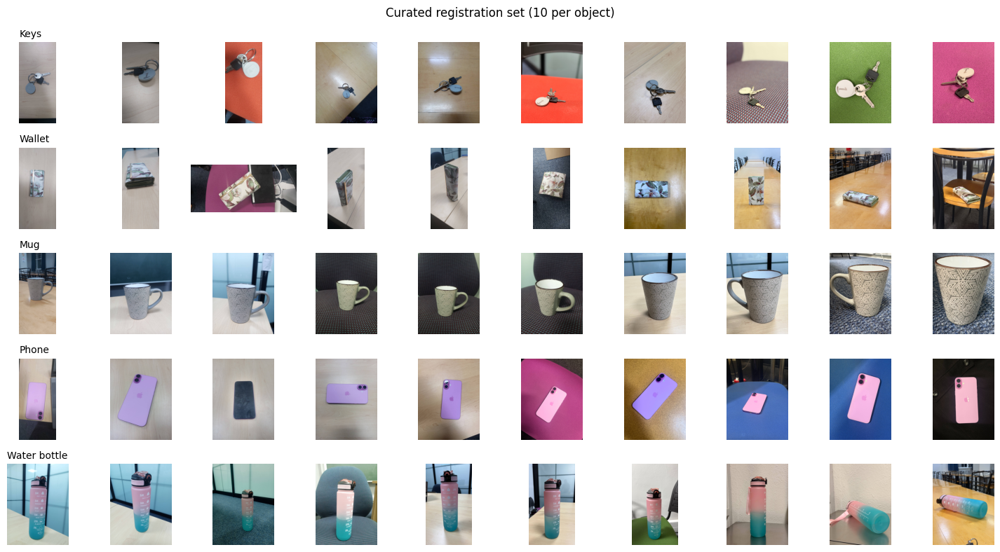

In [9]:
# B1: registration photos
reg_rows, seen_reg = [], set()
for p in IMAGES:
    o = REG_FOLDERS.get(p.parent.name.lower())
    if o and (o, p.name) not in seen_reg:
        seen_reg.add((o, p.name)); reg_rows.append({'object': o, 'file': p.name, 'path': str(p)})
reg = pd.DataFrame(reg_rows).sort_values(['object', 'file']).reset_index(drop=True)
assert set(reg.object) == set(OBJECTS), f'registration folders found: {sorted(set(reg.object))}'

CURATED = {   # 10 close-ups per object (see the note above). File names only.
    'Keys': ['20261113_194253', '20261113_194447', '20261113_194518', 'IMG_20261113_195830', 'IMG_20261113_195843',
             'IMG_7086', 'IMG_7089', 'IMG_7091', 'IMG_7095', 'IMG_7097'],
    'Wallet': ['20261113_194648', '20261113_194703', '20261113_194727', '20261113_194744', '20261113_194756',
               '20261113_194835', 'IMG_6784', 'IMG_6786', 'IMG_7119', 'IMG_7120'],
    'Mug': ['20261113_195717', 'IMG_20261113_194649', 'IMG_20261113_194743', 'IMG_20261113_194756',
            'IMG_20261113_194800', 'IMG_20261113_194812', 'IMG_6753', 'IMG_6754', 'IMG_6757', 'IMG_6759'],
    'Phone': ['20261115_205616', 'IMG_20261115_213229', 'IMG_20261115_213247', 'IMG_20261115_213320',
              'IMG_7673', 'IMG_7675', 'IMG_7677', 'IMG_7679', 'IMG_7680', 'IMG_7687'],
    'Water bottle': ['IMG_20261113_194308', 'IMG_20261113_194322', 'IMG_20261113_194422', 'IMG_20261113_194539',
                     'IMG_6766', 'IMG_6770', 'IMG_6773', 'IMG_7101', 'IMG_7102', 'IMG_7104'],
}
reg['curated'] = [Path(f).stem in CURATED[o] for o, f in zip(reg.object, reg.file)]
missing = {o: sorted(set(v) - set(reg[reg.object == o].file.map(lambda f: Path(f).stem))) for o, v in CURATED.items()}
assert not any(missing.values()), f'curated files not found: {missing}'

BOXES = {}
box_files = [p for p in FILES if p.name == 'registration_boxes.csv']
if box_files:
    b = pd.read_csv(box_files[0])
    BOXES = {(r.object, r.file): (r.x0, r.y0, r.x1, r.y1) for r in b.itertuples()}
    print(f'using {len(BOXES)} registration boxes')

def load_reg(row):
    im = load_upright(row.path, min_side=1024)
    if (row.object, row.file) in BOXES:
        x0, y0, x1, y1 = BOXES[(row.object, row.file)]; W, H = im.size
        im = im.crop((int(x0 * W), int(y0 * H), int(x1 * W), int(y1 * H)))
    return im

print(reg.groupby('object').agg(photos=('file', 'size'), curated=('curated', 'sum')))
fig, axes = plt.subplots(5, 10, figsize=(15, 8))
for r_, o in enumerate(OBJECTS):
    for c_, row in enumerate(reg[(reg.object == o) & reg.curated].itertuples()):
        axes[r_, c_].imshow(load_upright(row.path, min_side=160)); axes[r_, c_].axis('off')
    axes[r_, 0].set_title(o, loc='left', fontsize=10)
fig.suptitle('Curated registration set (10 per object)'); fig.tight_layout(); plt.show()

In [12]:
# B2: encoder and embedding function (CLS token, L2-normalised)
import torch
from transformers import AutoModel
torch.set_num_threads(os.cpu_count() or 2)
if DEVICE == 'auto': DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
ENCODER_IDS = {'dinov2_small': 'facebook/dinov2-small', 'dinov2_base': 'facebook/dinov2-base',
               'dinov3_small': 'facebook/dinov3-vits16-pretrain-lvd1689m'}   # DINOv3 is gated on Hugging Face

def hf_token():
    """Only needed for gated models (DINOv3). Kaggle: Add-ons -> Secrets -> HF_TOKEN. Colab/local: env HF_TOKEN."""
    if os.environ.get('HF_TOKEN'): return os.environ['HF_TOKEN']
    if ENV == 'kaggle':
        try:
            from kaggle_secrets import UserSecretsClient
            return UserSecretsClient().get_secret('HF_TOKEN')
        except Exception:
            return None
    return None

def load_encoder(name):
    kw = {'token': hf_token()} if name == 'dinov3_small' and hf_token() else {}
    try:
        return AutoModel.from_pretrained(ENCODER_IDS[name], **kw).eval().to(DEVICE)
    except Exception as e:
        hint = ('Kaggle: switch Internet On in the notebook settings (needs a phone-verified account). '
                if ENV == 'kaggle' else '')
        raise RuntimeError(f'Could not load {ENCODER_IDS[name]}. {hint}For DINOv3: accept the licence on its '
                           f'Hugging Face page and provide a token (Kaggle secret or env var HF_TOKEN).') from e

model = load_encoder(ENCODER)
MEAN = np.array([0.485, 0.456, 0.406], np.float32); STD = np.array([0.229, 0.224, 0.225], np.float32)

@torch.no_grad()
def embed(images, batch=16, net=None):
    net = net or model; out = []
    for k in range(0, len(images), batch):
        x = np.stack([(np.asarray(letterbox(im), np.float32) / 255 - MEAN) / STD for im in images[k:k + batch]])
        y = net(pixel_values=torch.from_numpy(x).permute(0, 3, 1, 2).to(DEVICE)).pooler_output   # CLS after final layer norm
        out.append(torch.nn.functional.normalize(y, dim=-1).cpu().numpy())
    return np.concatenate(out).astype(np.float32)

def cache_path(kind, enc=None):
    return CACHE / f'emb_{enc or ENCODER}_{INPUT_SIZE}_{kind}.npz'
TIMING = {}
print(ENCODER, '->', sum(p.numel() for p in model.parameters()) / 1e6, 'M parameters on', DEVICE)

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

dinov2_small -> 22.056576 M parameters on cuda


In [13]:
# B3: embed registration photos and Session 1 (zone crops + whole frames). Cached.
def embed_registration(enc=None, net=None):
    p = cache_path('registration', enc)
    if p.exists():
        d = np.load(p, allow_pickle=True)
        if list(d['files']) == list(reg.object + '/' + reg.file): return d['emb']
    t0 = time.perf_counter()
    E = np.concatenate([embed([load_reg(r) for r in chunk.itertuples()], net=net)
                        for _, chunk in reg.groupby(np.arange(len(reg)) // 32)])
    TIMING['registration_s'] = time.perf_counter() - t0
    np.savez(p, emb=E, files=np.array(reg.object + '/' + reg.file))
    return E

def embed_session(sess):
    """Returns zone-crop embeddings [n_frames, 8, D] and whole-frame embeddings [n_frames, D]."""
    p = cache_path(sess)
    if p.exists():
        d = np.load(p, allow_pickle=True)
        if list(d['frames']) == list(FR[sess].frame): return d['zones'], d['whole']
    Z, Wh, t_load, t_enc = [], [], 0.0, 0.0
    for row in FR[sess].itertuples():
        t0 = time.perf_counter(); img = load_upright(row.path, FRAME_MIN_SIDE); t1 = time.perf_counter()
        e = embed(zone_crops(img, sess) + [img]); t_enc += time.perf_counter() - t1; t_load += t1 - t0
        Z.append(e[:8]); Wh.append(e[8])
    n = len(FR[sess])
    TIMING[sess] = {'frames': n, 'decode_s_per_frame': t_load / n, 'encode_s_per_frame': t_enc / n,
                    'encode_ms_per_crop': 1000 * t_enc / (9 * n)}
    np.savez(p, zones=np.stack(Z), whole=np.stack(Wh), frames=np.array(FR[sess].frame),
             timing=json.dumps(TIMING[sess]))
    return np.stack(Z), np.stack(Wh)

E_reg = embed_registration()
EZ, EW = {}, {}
EZ['S1'], EW['S1'] = embed_session('S1')
print('registration', E_reg.shape, '| S1 zones', EZ['S1'].shape, '| S1 whole', EW['S1'].shape)
print('timing (this run only; cached runs are skipped):', json.dumps(TIMING, indent=1, default=float))

registration (207, 384) | S1 zones (20, 8, 384) | S1 whole (20, 384)
timing (this run only; cached runs are skipped): {
 "registration_s": 32.48806587800004,
 "S1": {
  "frames": 20,
  "decode_s_per_frame": 0.2817959232499902,
  "encode_s_per_frame": 0.2691281373000095,
  "encode_ms_per_crop": 29.90312636666772
 }
}


### Round 2 methods
B4 and B5 run only when `ROUND = 2` (A1). They embed Session 1 only; Session 2 goes through the frozen method in D2.

First-run cost: on a CPU, about 14 s per frame for tiles and 10 s per photo for OWLv2 on an 8-thread laptop, and likely 2-3x slower on Kaggle's CPU. So on a Kaggle CPU, expect roughly 1-1.5 hours for Part B and up to another hour in D2, depending on the winning method. A Kaggle GPU (T4) should take minutes. Everything is cached, and progress lines are printed while it runs. With **Persistence: Files only**, a second run skips the work.

  S1 tiles dinov2_small plain: 5/20, 4 s so far
  S1 tiles dinov2_small plain: 10/20, 8 s so far
  S1 tiles dinov2_small plain: 15/20, 12 s so far
  S1 tiles dinov2_small plain: 20/20, 16 s so far
S1 tiles dinov2_small plain: 2160 tiles (108 per frame), 0.5 s per frame when computed
  S1 tiles dinov2_small contrast: 5/20, 5 s so far
  S1 tiles dinov2_small contrast: 10/20, 9 s so far
  S1 tiles dinov2_small contrast: 15/20, 13 s so far
  S1 tiles dinov2_small contrast: 20/20, 17 s so far
S1 tiles dinov2_small contrast boost: 2160 tiles (108 per frame), 0.5 s per frame when computed


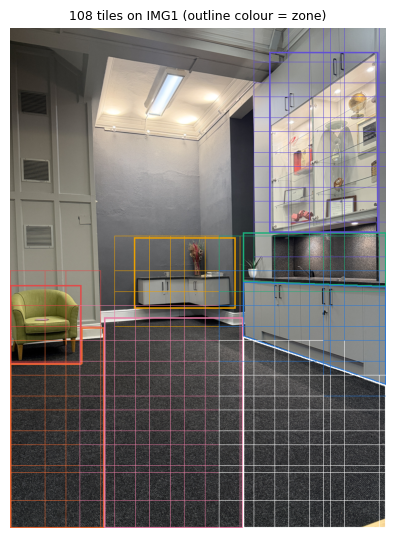

In [14]:
# B4 (round 2), option A: DINOv2 on overlapping tiles inside the zones. Cached; Part B embeds Session 1 only.
TILE, TILE_STRIDE = 224, 140   # pixels of the decoded frame (short side FRAME_MIN_SIDE = 1512, half the photo): a tile covers
                               # ~448 px of the original photo; 37% overlap, so an object up to ~84 px fits whole in some tile
TRY_DINOV2_BASE = False        # True also tries DINOv2-base tiles in C2 (about 3x slower than dinov2_small on CPU)
CONTRAST_OPTIONS = (False, True)   # C2 tries every round 2 method without and with the contrast boost (A4 enhance)
TILE_ENCODERS = ['dinov2_small'] + (['dinov2_base'] if TRY_DINOV2_BASE else [])

def progress(label, i, n, t0, every=5):
    """Print a progress line every few items, so long first runs visibly keep moving."""
    if (i + 1) % every == 0 or i + 1 == n: print(f'  {label}: {i + 1}/{n}, {time.perf_counter() - t0:.0f} s so far', flush=True)

_nets = {}
def get_net(enc):
    if enc == ENCODER: return model
    if enc not in _nets: _nets[enc] = load_encoder(enc)
    return _nets[enc]

def reg_emb(enc):
    return E_reg if enc == ENCODER else embed_registration(enc, get_net(enc))

def tile_grid(sess, W, H):
    """TILE x TILE boxes on a regular grid over the frame, each assigned to the zone that holds its centre. Tiles centred
    outside every zone are dropped; a zone that no tile centre falls in gets one tile on its own centre."""
    def starts(L):
        s = list(range(0, max(L - TILE, 0) + 1, TILE_STRIDE))
        return s + [L - TILE] if s[-1] + TILE < L else s
    boxes = np.array([(x, y, x + TILE, y + TILE) for y in starts(H) for x in starts(W)], float)
    zone = zone_of_points(sess, np.c_[(boxes[:, 0] + boxes[:, 2]) / 2 / W, (boxes[:, 1] + boxes[:, 3]) / 2 / H])
    boxes, zone = boxes[zone > 0], zone[zone > 0]
    for z in sorted(set(range(1, 9)) - set(zone.tolist())):
        x0, y0, x1, y1 = zone_region(sess, z)
        cx = min(max((x0 + x1) / 2 * W, TILE / 2), W - TILE / 2); cy = min(max((y0 + y1) / 2 * H, TILE / 2), H - TILE / 2)
        boxes = np.vstack([boxes, [cx - TILE / 2, cy - TILE / 2, cx + TILE / 2, cy + TILE / 2]]); zone = np.r_[zone, z]
    return boxes, zone

_tiles_mem = {}
def embed_tiles(sess, enc='dinov2_small', contrast=False):
    """Every tile of every frame: emb [T, D], frame_i [T], zone [T], box [T, 4] (normalised frame coords), timing."""
    p = CACHE / f'tiles_{enc}_{FRAME_MIN_SIDE}_{TILE}_{TILE_STRIDE}_{"clahe" if contrast else "plain"}_{sess}.npz'
    if p in _tiles_mem: return _tiles_mem[p]
    if p.exists():
        d = np.load(p, allow_pickle=True)
        if list(d['frames']) == list(FR[sess].frame):
            _tiles_mem[p] = {k: d[k] for k in ('emb', 'frame_i', 'zone', 'box')} | {'timing': json.loads(str(d['timing']))}
            return _tiles_mem[p]
    net, acc, t_load, t_enc = get_net(enc), {'emb': [], 'frame_i': [], 'zone': [], 'box': []}, 0.0, 0.0
    t_start = time.perf_counter()
    for i, row in enumerate(FR[sess].itertuples()):
        t0 = time.perf_counter(); img = enhance(load_frame(row.path), contrast); W, H = img.size
        boxes, zone = tile_grid(sess, W, H); t1 = time.perf_counter()
        acc['emb'].append(embed([img.crop(tuple(int(round(v)) for v in b)) for b in boxes], batch=32, net=net))
        t_enc += time.perf_counter() - t1; t_load += t1 - t0
        acc['frame_i'].append(np.full(len(boxes), i)); acc['zone'].append(zone); acc['box'].append(boxes / [W, H, W, H])
        progress(f"{sess} tiles {enc} {'contrast' if contrast else 'plain'}", i, len(FR[sess]), t_start)
    out = {k: np.concatenate(v) for k, v in acc.items()}; n = len(FR[sess])
    timing = {'frames': n, 'tiles_per_frame': len(out['zone']) / n, 'decode_s_per_frame': t_load / n, 'encode_s_per_frame': t_enc / n}
    np.savez(p, **out, frames=np.array(FR[sess].frame), timing=json.dumps(timing))
    _tiles_mem[p] = out | {'timing': timing}
    return _tiles_mem[p]

if ROUND >= 2:
    for enc in TILE_ENCODERS:
        for c in CONTRAST_OPTIONS:
            T = embed_tiles('S1', enc, c)
            print(f"S1 tiles {enc} {'contrast boost' if c else 'plain'}: {T['emb'].shape[0]} tiles "
                  f"({T['timing']['tiles_per_frame']:.0f} per frame), {T['timing']['encode_s_per_frame']:.1f} s per frame when computed")
    # what the tiles look like on one frame: tile centres coloured by zone
    img0 = load_frame(FR['S1'].path[0]); b0, z0 = tile_grid('S1', *img0.size)
    over = draw_zones(img0, 'S1', scale=2); d = ImageDraw.Draw(over)
    for b, z in zip(b0 / 2, z0):
        d.rectangle(list(b), outline=ZONE_COLOURS[z - 1], width=1)
    plt.figure(figsize=(5, 6.5)); plt.imshow(over); plt.axis('off')
    plt.title(f'{len(b0)} tiles on {FR["S1"].frame[0]} (outline colour = zone)', fontsize=9); plt.show()


S1 OWLv2 plain: 3600 boxes per frame, 0.5 s per frame when computed
S1 OWLv2 contrast boost: 3600 boxes per frame, 0.5 s per frame when computed


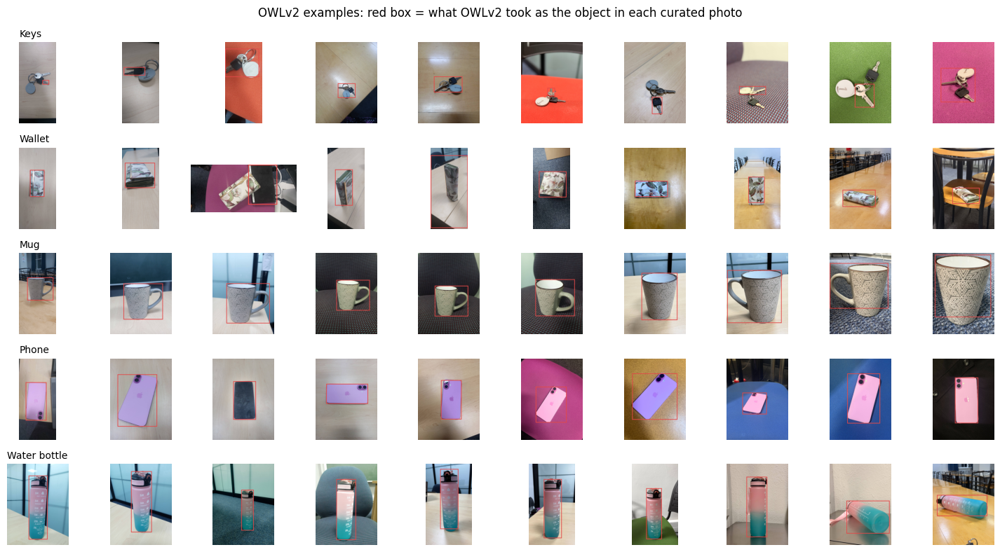

In [17]:
# B5 (round 2), option B: OWLv2 one-shot detection. Each curated registration photo is an example; OWLv2 scores every
# box in a frame against it, and a box counts for the zone that holds its centre. Cached; Part B runs Session 1 only.
from transformers import Owlv2ForObjectDetection
OWL_ID = 'google/owlv2-base-patch16-ensemble'
OWL_REG_SET = 'curated'    # examples = the 10 close-ups per object. In a wide shot OWLv2 would take the most object-like
                           # thing in the photo as the example, which is often not the registered object.
OWL_MAX_BOX_AREA = 0.05    # ignore boxes covering more than 5% of the frame: the five objects are small; big boxes are furniture
CLIP_MEAN = np.array([0.48145466, 0.4578275, 0.40821073], np.float32)
CLIP_STD = np.array([0.26862954, 0.26130258, 0.27577711], np.float32)

_owl = {}
def get_owl():
    if 'm' not in _owl:
        try:
            _owl['m'] = Owlv2ForObjectDetection.from_pretrained(OWL_ID).eval().to(DEVICE)
        except Exception as e:
            raise RuntimeError(f'Could not load {OWL_ID}. ' + ('Kaggle: switch Internet On in the notebook settings.'
                                                               if ENV == 'kaggle' else '')) from e
    return _owl['m']

@torch.no_grad()
def owl_features(img):
    """Per-box outputs for one image: unit class embeddings ce [P, 512], logit shift and scale [P], boxes [P, 4] as
    normalised (x0, y0, x1, y1) on the image, objectness [P]. P = 3600 (a 60 x 60 grid at 960 px)."""
    m = get_owl(); size = m.config.vision_config.image_size; W, H = img.size; side = max(W, H)
    canvas = Image.new('RGB', (side, side), (128, 128, 128)); canvas.paste(img, (0, 0))   # pad bottom/right, like OWLv2's processor
    x = (np.asarray(canvas.resize((size, size), Image.BICUBIC), np.float32) / 255 - CLIP_MEAN) / CLIP_STD
    fmap = m.image_embedder(pixel_values=torch.from_numpy(x).permute(2, 0, 1)[None].to(DEVICE))[0]
    feats = fmap.reshape(1, -1, fmap.shape[-1])
    ce = m.class_predictor(feats)[1][0]; ce = ce / (ce.norm(dim=-1, keepdim=True) + 1e-6)
    head = m.class_head
    shift = head.logit_shift(feats)[0, :, 0]; scale = head.elu(head.logit_scale(feats))[0, :, 0] + 1
    cx, cy, w, h = m.box_predictor(feats, fmap)[0].unbind(-1)
    box = torch.stack([(cx - w / 2) * side / W, (cy - h / 2) * side / H, (cx + w / 2) * side / W, (cy + h / 2) * side / H], -1)
    return {'ce': ce.cpu().numpy(), 'shift': shift.cpu().numpy(), 'scale': scale.cpu().numpy(),
            'box': box.clamp(0, 1).cpu().numpy(), 'obj': m.objectness_predictor(feats)[0].cpu().numpy()}

def owl_logits(F, q):
    """OWLv2's class-head logits for boxes F against unit query embeddings q [Q, 512] -> [P, Q]."""
    return (F['ce'].astype(np.float32) @ q.T + F['shift'][:, None]) * F['scale'][:, None]

_owl_mem = {}
def owl_queries():
    """One example embedding per registration photo: the photo's most object-like box (highest objectness)."""
    rows = reg[reg.curated] if OWL_REG_SET == 'curated' else reg
    files = list(rows.object + '/' + rows.file); p = CACHE / f'owl_queries_{OWL_REG_SET}.npz'
    if p in _owl_mem: return _owl_mem[p]
    if p.exists():
        d = np.load(p, allow_pickle=True)
        if list(d['files']) == files:
            _owl_mem[p] = {k: d[k] for k in ('emb', 'box', 'object')}; return _owl_mem[p]
    emb, box, t_start = [], [], time.perf_counter()
    for i, r in enumerate(rows.itertuples()):
        F = owl_features(load_reg(r)); j = int(F['obj'].argmax())
        emb.append(F['ce'][j]); box.append(F['box'][j])
        progress('OWLv2 example photos', i, len(rows), t_start, every=10)
    _owl_mem[p] = {'emb': np.stack(emb).astype(np.float32), 'box': np.stack(box), 'object': np.array(rows.object.tolist())}
    np.savez(p, **_owl_mem[p], files=np.array(files))
    return _owl_mem[p]

def owl_session(sess, contrast=False):
    """OWLv2 per-box outputs for every frame of a session (stacked on a leading frame axis), plus timing."""
    p = CACHE / f'owl_{FRAME_MIN_SIDE}_{"clahe" if contrast else "plain"}_{sess}.npz'
    if p in _owl_mem: return _owl_mem[p]
    keys = ('ce', 'shift', 'scale', 'box', 'obj')
    if p.exists():
        d = np.load(p, allow_pickle=True)
        if list(d['frames']) == list(FR[sess].frame):
            _owl_mem[p] = {k: d[k] for k in keys} | {'timing': json.loads(str(d['timing']))}; return _owl_mem[p]
    acc, t_load, t_enc, t_start = {k: [] for k in keys}, 0.0, 0.0, time.perf_counter()
    for i, row in enumerate(FR[sess].itertuples()):
        t0 = time.perf_counter(); img = enhance(load_frame(row.path), contrast); t1 = time.perf_counter()
        F = owl_features(img); F['ce'] = F['ce'].astype(np.float16); t_enc += time.perf_counter() - t1; t_load += t1 - t0
        for k in keys: acc[k].append(F[k])
        progress(f"{sess} OWLv2 {'contrast' if contrast else 'plain'}", i, len(FR[sess]), t_start)
    out = {k: np.stack(v) for k, v in acc.items()}; n = len(FR[sess])
    timing = {'frames': n, 'decode_s_per_frame': t_load / n, 'encode_s_per_frame': t_enc / n}
    np.savez(p, **out, frames=np.array(FR[sess].frame), timing=json.dumps(timing))
    _owl_mem[p] = out | {'timing': timing}
    return _owl_mem[p]

if ROUND >= 2:
    OWLQ = owl_queries()
    for c in CONTRAST_OPTIONS:
        F = owl_session('S1', c)
        print(f"S1 OWLv2 {'contrast boost' if c else 'plain'}: {F['box'].shape[1]} boxes per frame, "
              f"{F['timing']['encode_s_per_frame']:.1f} s per frame when computed")
    # check the examples: the box OWLv2 took as "the object" in each curated photo
    q_rows = (reg[reg.curated] if OWL_REG_SET == 'curated' else reg).reset_index(drop=True)
    fig, axes = plt.subplots(5, 10, figsize=(15, 8))
    for r_, o in enumerate(OBJECTS):
        for c_, (j, row) in enumerate(q_rows[q_rows.object == o].head(10).iterrows()):
            im = load_upright(row.path, min_side=200); W, H = im.size; b = OWLQ['box'][j]
            ImageDraw.Draw(im).rectangle([b[0] * W, b[1] * H, b[2] * W, b[3] * H], outline='#e34948', width=4)
            axes[r_, c_].imshow(im)
        for a in axes[r_]: a.axis('off')
        axes[r_, 0].set_title(o, loc='left', fontsize=10)
    fig.suptitle('OWLv2 examples: red box = what OWLv2 took as the object in each curated photo'); fig.tight_layout(); plt.show()
    


## Part C: Session 1 only: diagnostic, threshold, freeze
**Round 2 note.** Round 1 froze the whole-zone method and evaluated it on Session 2, where it failed: on Session 1 the right zone ranked first about as often as chance, so the threshold rule settled on never sighting anything. Round 2 compares the round 1 settings with tiles (B4) and OWLv2 (B5), each with and without the contrast boost, using the same rule below, on Session 1 only. The question list for Session 2 stays the same file as in round 1. **Round 3** adds the proposal's usual-zone prior ("match × prior") to round 2's frozen method and keeps its threshold: no new selection, because a prior built from the Session 1 log would look perfect on Session 1 and bias any choice made there. With 16 candidates and only 20 frames, the winner's Session 1 numbers are optimistic; the Session 2 numbers are the ones to report.

**Score:** `S[frame, zone, object]`, higher = more like the object. For the DINOv2 methods it is the cosine similarity between a zone crop (`zone`) or the zone's best tile (`tiles`) and the object's registration embeddings: either the cosine to the mean prototype (`mean`) or the best single photo (`max`). For OWLv2 it is the detector's logit for the best box centred in the zone, against the mean example (`mean`) or the best single example (`max`).

**Per frame and object:** the best zone is the argmax over the 8 zones. The object counts as *sighted* if that best score is at least τ.

**Labels (S1 log):** *present* means visible or partly hidden in a zone; *absent* means removed or not in the room yet. Carried and person-blocked frames are left out.

**Threshold rule, declared before looking:** choose τ to maximise S1 balanced accuracy. Here *present-correct* = sighted **and** in the right zone, and *absent-correct* = not sighted. If τ values tie, take the highest (fewer false sightings). The candidate settings (registration set × prototype, plus any encoder whose cache exists) are ranked by the same number.

With 20 frames and only 19 absent pairs, these S1 numbers are rough. Treat differences of a few points as noise.

A similarity score is **not** a probability or a confidence; accuracy is reported separately.

In [20]:
# C1: scoring functions (shared by S1 and S2)
def score(E, E_reg_, reg_set, proto):
    """E: [..., D] unit vectors -> similarity [..., n_objects]."""
    out = []
    for o in OBJECTS:
        R = E_reg_[((reg.object == o) & (reg.curated if reg_set == 'curated' else True)).to_numpy()]
        if proto == 'mean':
            p = R.mean(0); out.append(E @ (p / np.linalg.norm(p)))
        else:
            out.append((E @ R.T).max(-1))
    return np.stack(out, -1)

def auc(pos, neg):
    """P(score of a present example > score of an absent one), ties count half."""
    if len(pos) == 0 or len(neg) == 0: return np.nan
    allv = np.concatenate([pos, neg]); ranks = pd.Series(allv).rank().to_numpy()
    return (ranks[:len(pos)].sum() - len(pos) * (len(pos) + 1) / 2) / (len(pos) * len(neg))

PRESENT, ABSENT = ('visible', 'partly_hidden'), ('removed', 'not_in_room')
SPEC_KEYS = ('method', 'encoder', 'contrast', 'reg_set', 'proto')

# Round 3: the proposal's usual-zone prior, from the Session 1 log (calibration data), Laplace-smoothed so no zone is ruled out
PRIOR_ALPHA = 1.0
_s1_counts = np.stack([np.bincount(GT['S1']['zone'][np.isin(GT['S1']['state'][:, k], PRESENT), k], minlength=9)[1:]
                       for k in range(len(OBJECTS))], 1)                                          # [8 zones, objects]
ZONE_PRIOR = (_s1_counts + PRIOR_ALPHA) / (_s1_counts.sum(0, keepdims=True) + 8 * PRIOR_ALPHA)

def zone_choice(S, m):
    """Chosen zone (0-based) per frame and object from S[..., 8, objects]. Without the prior: the best-scoring zone.
    With it (round 3, the proposal's "match x prior"): the zone maximising match x usual-zone prior, where match is the
    detector probability (OWLv2) or (1 + cosine) / 2 (DINOv2). The prior only chooses between zones; whether anything
    is sighted still depends on the best score alone, so the prior never creates a sighting."""
    if not (m and m.get('prior')): return S.argmax(-2)
    match = 1 / (1 + np.exp(-S)) if m['method'] == 'owlv2' else (1 + S) / 2
    return (match * ZONE_PRIOR).argmax(-2)

def pair_arrays(S, G, m=None):
    """Per (frame, object): best score, chosen zone (zone_choice for setting m), present/absent masks, true zone."""
    best, arg = S.max(1), (zone_choice(S, m) if m else S.argmax(1)) + 1
    pres, absn = np.isin(G['state'], PRESENT), np.isin(G['state'], ABSENT)
    return best, arg, pres, absn, G['zone']

def rates_at(tau, best, arg, pres, absn, ztrue, need_zone=True):
    sighted = best >= tau
    hit = sighted & (arg == ztrue) if need_zone else sighted
    caught = hit[pres]
    return {'right_zone_rate' if need_zone else 'caught_rate': caught.mean(),
            'sighted_rate': sighted[pres].mean(), 'false_sighting_rate': sighted[absn].mean(),
            'balanced_acc': 0.5 * (caught.mean() + (~sighted[absn]).mean())}

def choose_tau(best, arg, pres, absn, ztrue, need_zone=True):
    v = np.unique(best[pres | absn])
    cands = np.concatenate([[v[0] - 1e-3], (v[1:] + v[:-1]) / 2, [v[-1] + 1e-3]])
    accs = np.array([rates_at(t, best, arg, pres, absn, ztrue, need_zone)['balanced_acc'] for t in cands])
    return float(cands[np.flatnonzero(accs == accs.max())[-1]])     # ties -> highest tau
def spec_name(m):
    return ('/'.join([m['method'], m['encoder'], 'clahe' if m['contrast'] else 'plain', m['reg_set'], m['proto']])
            + ('+prior' if m.get('prior') else ''))

def describe_spec(m):
    """A setting in plain words, for tables and the report."""
    what = {'zone': 'DINOv2, one crop per zone', 'tiles': 'DINOv2 on tiles inside each zone',
            'owlv2': 'OWLv2 object detector'}[m['method']]
    return (f"{what}; {'with' if m['contrast'] else 'no'} contrast boost; "
            f"{'curated close-ups' if m['reg_set'] == 'curated' else 'all registration photos'}; "
            f"{'average of the examples' if m['proto'] == 'mean' else 'best single example'}"
            + ('; plus the usual-zone prior (match x prior)' if m.get('prior') else ''))

def spec_of(cfg):
    """Method spec from a frozen config (round 1 configs have no 'method' or 'contrast' key)."""
    return {'method': cfg.get('method', 'zone'), 'encoder': cfg['encoder'], 'contrast': bool(cfg.get('contrast', False)),
            'reg_set': cfg['reg_set'], 'proto': cfg['proto'], 'prior': bool(cfg.get('prior', False))}

def best_per_group(group, values, n_groups):
    """Max of values within each group id (0..n_groups-1) and the index of that max; -inf and -1 where a group is empty."""
    best, arg = np.full(n_groups, -np.inf), np.full(n_groups, -1)
    if len(values):
        idx = pd.Series(values).groupby(np.asarray(group)).idxmax()
        best[idx.index.to_numpy()] = values[idx.to_numpy()]; arg[idx.index.to_numpy()] = idx.to_numpy()
    return best, arg

_score_cache = {}
def method_scores(m, sess):
    """S[frame, zone, object] (higher = more like the object) and the evidence box B[frame, zone, object, 4] in
    normalised frame coords, for one candidate setting m. Serves both Session 1 (Part C) and Session 2 (Part D)."""
    key = (spec_name({**m, 'prior': False}), sess)      # the prior changes the zone choice, not the scores
    if key in _score_cache: return _score_cache[key]
    n, K = len(FR[sess]), len(OBJECTS)
    S, B = np.full((n, 8, K), -np.inf), np.zeros((n, 8, K, 4))
    if m['method'] == 'zone':        # round 1: one embedding per whole zone crop
        Ez = EZ[sess] if m['encoder'] == ENCODER else load_cached(m['encoder'], sess)['zones']
        S = score(Ez, reg_emb(m['encoder']), m['reg_set'], m['proto'])
        B[:] = np.array([zone_region(sess, z) for z in range(1, 9)])[None, :, None, :]
    elif m['method'] == 'tiles':     # round 2, option A: the best tile inside each zone
        T = embed_tiles(sess, m['encoder'], m['contrast'])
        s = score(T['emb'], reg_emb(m['encoder']), m['reg_set'], m['proto'])          # [tiles, objects]
        g = T['frame_i'] * 8 + T['zone'] - 1
        for k in range(K):
            best, arg = best_per_group(g, s[:, k], n * 8)
            S[:, :, k] = best.reshape(n, 8); ok = arg >= 0
            B.reshape(n * 8, K, 4)[ok, k] = T['box'][arg[ok]]
    elif m['method'] == 'owlv2':     # round 2, option B: the best detected box centred in each zone
        F, Q = owl_session(sess, m['contrast']), owl_queries()
        for i in range(n):
            bx = F['box'][i]; area = (bx[:, 2] - bx[:, 0]) * (bx[:, 3] - bx[:, 1])
            zone = zone_of_points(sess, np.c_[(bx[:, 0] + bx[:, 2]) / 2, (bx[:, 1] + bx[:, 3]) / 2])
            ok = (zone > 0) & (area <= OWL_MAX_BOX_AREA)
            Fi = {k_: F[k_][i][ok] for k_ in ('ce', 'shift', 'scale')}
            for k, o in enumerate(OBJECTS):
                q = Q['emb'][Q['object'] == o]
                if m['proto'] == 'mean': q = q.mean(0, keepdims=True); q = q / np.linalg.norm(q)
                best, arg = best_per_group(zone[ok] - 1, owl_logits(Fi, q).max(1), 8)
                S[i, :, k] = best; B[i, arg >= 0, k] = bx[ok][arg[arg >= 0]]
    else:
        raise ValueError(m['method'])
    finite = S[np.isfinite(S)]
    S = np.where(np.isfinite(S), S, (finite.min() if finite.size else 0.0) - 1.0)   # a zone with no box scores lowest
    _score_cache[key] = (S, B)
    return S, B

def method_timing(m, sess):
    if m['method'] == 'zone': return json.loads(str(np.load(cache_path(sess, m['encoder']), allow_pickle=True)['timing']))
    if m['method'] == 'tiles': return embed_tiles(sess, m['encoder'], m['contrast'])['timing']
    return owl_session(sess, m['contrast'])['timing']


In [21]:
# C2: S1 diagnostic for every candidate setting (round 1: whole-zone crops; round 2+: also tiles and OWLv2)
from IPython.display import display   # IPython puts display in builtins, not globals()
def available_encoders():
    return [e for e in ENCODER_IDS
            if (CACHE / f'emb_{e}_{INPUT_SIZE}_S1.npz').exists() and (CACHE / f'emb_{e}_{INPUT_SIZE}_registration.npz').exists()]

def load_cached(enc, kind):
    return np.load(CACHE / f'emb_{enc}_{INPUT_SIZE}_{kind}.npz', allow_pickle=True)

CANDIDATES = [dict(method='zone', encoder=e, contrast=False, reg_set=r, proto=p)
              for e in available_encoders() for r in ('curated', 'all') for p in ('mean', 'max')]
if ROUND >= 2:
    CANDIDATES += [dict(method='tiles', encoder=e, contrast=c, reg_set=r, proto=p)
                   for e in TILE_ENCODERS for c in CONTRAST_OPTIONS for r in ('curated', 'all') for p in ('mean', 'max')]
    CANDIDATES += [dict(method='owlv2', encoder='owlv2_base', contrast=c, reg_set=OWL_REG_SET, proto=p)
                   for c in CONTRAST_OPTIONS for p in ('mean', 'max')]

def diagnose(m, tau=None):
    """Session 1 numbers for one setting. tau=None chooses tau by the declared rule; otherwise uses the given tau."""
    S, _ = method_scores(m, 'S1')
    best, arg, pres, absn, zt = pair_arrays(S, GT['S1'], m)
    if tau is None: tau = choose_tau(best, arg, pres, absn, zt)
    r = rates_at(tau, best, arg, pres, absn, zt)
    pos = np.concatenate([S[pres[:, k], zt[pres[:, k], k] - 1, k] for k in range(len(OBJECTS))])
    negmask = np.ones(S.shape, bool)
    for k in range(len(OBJECTS)):
        negmask[:, :, k] &= (pres[:, k] | absn[:, k])[:, None]
        ii = np.flatnonzero(pres[:, k]); negmask[ii, zt[ii, k] - 1, k] = False
    row = {**m, 'tau': round(float(tau), 4), 'zone_auc': auc(pos, S[negmask]), 'top1_zone_when_present': (arg == zt)[pres].mean(), **r}
    objs = []
    for k, o in enumerate(OBJECTS):
        pk = S[pres[:, k], zt[pres[:, k], k] - 1, k]; nk = S[:, :, k][negmask[:, :, k]]
        objs.append({**m, 'object': o, 'present_frames': int(pres[:, k].sum()), 'absent_frames': int(absn[:, k].sum()),
                     'zone_auc': auc(pk, nk), 'top1_zone': (arg[:, k] == zt[:, k])[pres[:, k]].mean()})
    return row, objs

diag, per_object = [], []
for m in CANDIDATES:
    row, objs = diagnose(m); diag.append(row); per_object += objs
diag = pd.DataFrame(diag).sort_values(['balanced_acc', 'zone_auc'], ascending=False).reset_index(drop=True)
per_object = pd.DataFrame(per_object)
pd.set_option('display.precision', 3); pd.set_option('display.width', 200)
print(f'round {ROUND}: {len(diag)} candidate settings, ranked by S1 balanced accuracy, then zone_auc.'
      + (' Round 3 keeps round 2\'s choice and adds the prior in C4.' if ROUND >= 3 else ''))
C2_VIEW = pd.DataFrame({
    'Setting': [describe_spec(r) for r in diag.to_dict('records')],
    'Right zone ranked first': [f'{100 * v:.0f}%' for v in diag.top1_zone_when_present],
    'Zone AUC': diag.zone_auc.round(2),
    'Sighted in right zone': [f'{100 * v:.0f}%' for v in diag.right_zone_rate],
    'False sightings': [f'{100 * v:.0f}%' for v in diag.false_sighting_rate],
    'Balanced accuracy': diag.balanced_acc.round(3), 'Threshold τ': diag.tau})
C2_VIEW.index = pd.RangeIndex(1, len(C2_VIEW) + 1, name='rank')
print('Rank 1 (highlighted) is what C4 freezes unless MANUAL_CHOICE is set. "Right zone ranked first" and zone AUC show whether')
print('the scores find the objects at all; balanced accuracy is the declared rule. Chance: 12.5% ranked first, AUC 0.5.')
display(C2_VIEW.style.apply(lambda r: ['font-weight: 600; background-color: #e6effa' if r.name == 1 else '' for _ in r], axis=1))


round 3: 16 candidate settings, ranked by S1 balanced accuracy, then zone_auc. Round 3 keeps round 2's choice and adds the prior in C4.
Rank 1 (highlighted) is what C4 freezes unless MANUAL_CHOICE is set. "Right zone ranked first" and zone AUC show whether
the scores find the objects at all; balanced accuracy is the declared rule. Chance: 12.5% ranked first, AUC 0.5.


,Setting,Right zone ranked first,Zone AUC,Sighted in right zone,False sightings,Balanced accuracy,Threshold τ
rank,,,,,,,
1,OWLv2 object detector; with contrast boost; curated close-ups; best single example,66%,0.810000,36%,0%,0.681000,5.283800
2,OWLv2 object detector; with contrast boost; curated close-ups; average of the examples,68%,0.820000,32%,0%,0.662000,4.932700
3,OWLv2 object detector; no contrast boost; curated close-ups; average of the examples,65%,0.830000,30%,0%,0.650000,4.886800
4,OWLv2 object detector; no contrast boost; curated close-ups; best single example,69%,0.810000,29%,0%,0.644000,5.471900
5,DINOv2 on tiles inside each zone; no contrast boost; curated close-ups; average of the examples,30%,0.550000,8%,0%,0.538000,0.390100
6,DINOv2 on tiles inside each zone; with contrast boost; curated close-ups; average of the examples,30%,0.540000,8%,0%,0.538000,0.379600
7,DINOv2 on tiles inside each zone; with contrast boost; curated close-ups; best single example,26%,0.520000,8%,0%,0.538000,0.454800
8,DINOv2 on tiles inside each zone; no contrast boost; all registration photos; average of the examples,34%,0.500000,8%,0%,0.538000,0.515600
9,DINOv2 on tiles inside each zone; with contrast boost; all registration photos; average of the examples,34%,0.490000,8%,0%,0.538000,0.502100


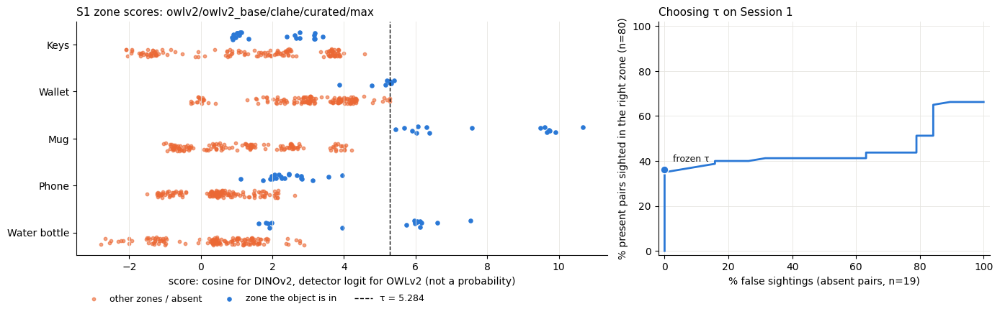

   method     encoder  contrast  reg_set proto        object  present_frames  absent_frames  zone_auc  top1_zone
75  owlv2  owlv2_base      True  curated   max          Keys              20              0     0.548      0.000
76  owlv2  owlv2_base      True  curated   max        Wallet               8             12     0.949      0.875
77  owlv2  owlv2_base      True  curated   max           Mug              15              4     1.000      1.000
78  owlv2  owlv2_base      True  curated   max         Phone              20              0     0.965      0.750
79  owlv2  owlv2_base      True  curated   max  Water bottle              17              3     0.980      0.941


In [22]:
# C3: look at the best setting: per-object score strips and the caught vs false-sighting curve
top = diag.iloc[0]
TOP = {k: top[k] for k in SPEC_KEYS}
S1s = method_scores(TOP, 'S1')[0]
best, arg, pres, absn, zt = pair_arrays(S1s, GT['S1'], TOP)
BLUE, ORANGE, INK, MUTED = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e'
rng = np.random.default_rng(0)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [1.6, 1]})
for k, o in enumerate(OBJECTS):
    ii = np.flatnonzero(pres[:, k]); pos = S1s[ii, zt[ii, k] - 1, k]
    m = np.ones((len(S1s), 8), bool); m[~(pres[:, k] | absn[:, k])] = False; m[ii, zt[ii, k] - 1] = False
    neg = S1s[:, :, k][m]
    ax1.scatter(neg, k + 0.18 + rng.uniform(-.08, .08, len(neg)), s=10, c=ORANGE, alpha=.6, label='other zones / absent' if k == 0 else None)
    ax1.scatter(pos, k - 0.18 + rng.uniform(-.08, .08, len(pos)), s=14, c=BLUE, label='zone the object is in' if k == 0 else None)
ax1.axvline(top.tau, color=INK, lw=1, ls='--', label=f'τ = {top.tau:.3f}')
ax1.set_yticks(range(len(OBJECTS)), OBJECTS); ax1.invert_yaxis(); ax1.set_xlabel('score: cosine for DINOv2, detector logit for OWLv2 (not a probability)')
ax1.legend(loc='upper left', bbox_to_anchor=(0, -0.13), ncol=3, frameon=False, fontsize=9); ax1.grid(axis='x', color='#e6e5e0', lw=.6)
ax1.set_title(f'S1 zone scores: {spec_name(TOP)}', loc='left', fontsize=11)
taus = np.linspace(best.min() - 1e-3, best.max() + 1e-3, 200)
cur = np.array([[rates_at(t, best, arg, pres, absn, zt)[k] for k in ('false_sighting_rate', 'right_zone_rate')] for t in taus])
ax2.plot(cur[:, 0] * 100, cur[:, 1] * 100, color=BLUE, lw=2)
r = rates_at(top.tau, best, arg, pres, absn, zt)
ax2.scatter([r['false_sighting_rate'] * 100], [r['right_zone_rate'] * 100], s=60, c=BLUE, edgecolor='white', zorder=3)
ax2.annotate('frozen τ', (r['false_sighting_rate'] * 100, r['right_zone_rate'] * 100), xytext=(8, 8), textcoords='offset points', fontsize=9, color=INK)
ax2.set_xlabel(f'% false sightings (absent pairs, n={absn.sum()})'); ax2.set_ylabel(f'% present pairs sighted in the right zone (n={pres.sum()})')
ax2.set_xlim(-2, 102); ax2.set_ylim(-2, 102); ax2.grid(color='#e6e5e0', lw=.6)
ax2.set_title('Choosing τ on Session 1', loc='left', fontsize=11)
for ax in (ax1, ax2): [ax.spines[s].set_visible(False) for s in ('top', 'right')]
fig.tight_layout(); plt.show()
C3_FIG = fig          # kept for the D7 report
print(per_object[np.all([per_object[k] == v for k, v in TOP.items()], axis=0)])

In [23]:
# C4: FREEZE. Writes the round's frozen config. Decide here, before Part D touches Session 2.
# CHECKPOINT: look at C2/C3 first. If zone_auc is near 0.5 and top-1 zone near 0.125 for most objects,
# the method is not finding the objects. Stop here and discuss a change of method BEFORE freezing;
# a method change after Session 2 results is a new round and must be reported as one.
MANUAL_CHOICE = None    # e.g. {'method': 'tiles', 'encoder': 'dinov2_small', 'contrast': False, 'reg_set': 'all', 'proto': 'max'}
                        # None = round 1-2: C2's top row; round 3: round 2's frozen setting (C2's top row if none exists)
FORCE_REFREEZE = False  # True = replace this round's freeze; refused once this round's Session 2 results exist
cfg_path = round_file('frozen_config.json')
s2_done = round_file('s2_results.csv').exists()

def row_spec(row):
    return {k: (bool(row[k]) if k == 'contrast' else str(row[k])) for k in SPEC_KEYS}

if cfg_path.exists() and not FORCE_REFREEZE:
    cfg = json.loads(cfg_path.read_text())
    print(f"Round {ROUND} already frozen at {cfg['frozen_at']} ({describe_spec(spec_of(cfg))}, tau {cfg['tau_zone']:.4f}); keeping it."
          + (' Session 2 results exist.' if s2_done else ''))
elif FORCE_REFREEZE and s2_done:
    raise RuntimeError(f'Round {ROUND} Session 2 results already exist; refusing to re-freeze. Report the frozen setting you have.')
else:
    r2_path = CACHE / 'frozen_config_r2.json'
    if MANUAL_CHOICE is not None:
        pick = diag[np.all([diag[k] == v for k, v in MANUAL_CHOICE.items()], axis=0)].iloc[0]
        base, tau, base_from = row_spec(pick), float(pick.tau), 'manual'
    elif ROUND >= 3 and r2_path.exists():
        c2 = json.loads(r2_path.read_text()); base, tau, base_from = spec_of(c2), float(c2['tau_zone']), 'round 2 freeze'
    else:
        base, tau, base_from = row_spec(diag.iloc[0]), float(diag.iloc[0].tau), 'S1 balanced accuracy, then zone_auc (C2 top row)'
    base.pop('prior', None)
    spec = {**base, 'prior': ROUND >= 3}
    m1, _ = diagnose(spec, tau)          # Session 1 numbers for the frozen setting at its frozen tau
    # whole-frame baseline: DINOv2 embedding of the whole photo (as in round 1), with the chosen registration set and prototype
    W1 = score(EW['S1'], E_reg, spec['reg_set'], spec['proto'])
    pres1, absn1 = np.isin(GT['S1']['state'], PRESENT), np.isin(GT['S1']['state'], ABSENT)
    tau_w = choose_tau(W1, None, pres1, absn1, None, need_zone=False)
    rw = rates_at(tau_w, W1, None, pres1, absn1, None, need_zone=False)
    # S1 zone prior: frames each object was present in each zone -> usual zone
    counts = {o: np.bincount(GT['S1']['zone'][pres1[:, k], k], minlength=9)[1:] for k, o in enumerate(OBJECTS)}
    usual = {o: int(np.argmax(c)) + 1 for o, c in counts.items()}
    settings = ({'tile': TILE, 'stride': TILE_STRIDE, 'frame_min_side': FRAME_MIN_SIDE} if spec['method'] == 'tiles' else
                {'model': OWL_ID, 'examples': OWL_REG_SET, 'max_box_area': OWL_MAX_BOX_AREA, 'frame_min_side': FRAME_MIN_SIDE}
                if spec['method'] == 'owlv2' else {})
    if spec['prior']:
        settings['prior'] = {'from': 'Session 1 log (zone counts while present)', 'laplace_alpha': PRIOR_ALPHA,
                             'match': 'sigmoid(logit)' if spec['method'] == 'owlv2' else '(1 + cosine) / 2',
                             'note': 'S1 metrics with the prior are optimistic: the prior comes from the S1 log'}
    cfg = {'round': ROUND, **spec, 'input_size': INPUT_SIZE, 'method_settings': settings,
           'tau_zone': tau, 'tau_whole_frame': tau_w,
           'whole_frame_baseline': {'encoder': ENCODER, 'reg_set': spec['reg_set'], 'proto': spec['proto']},
           'usual_zone_S1': usual, 'zone_prior_counts_S1': {o: c.tolist() for o, c in counts.items()},
           'S1_metrics_zone': {k: float(m1[k]) for k in ('zone_auc', 'top1_zone_when_present', 'right_zone_rate',
                                                       'false_sighting_rate', 'balanced_acc')},
           'S1_metrics_whole_frame': {k: float(v) for k, v in rw.items()},
           'candidates_compared': len(diag), 'chosen_by': base_from + (' + usual-zone prior (proposal)' if spec['prior'] else ''),
           'frozen_at': dt.datetime.now().isoformat(timespec='seconds')}
    cfg_path.write_text(json.dumps(cfg, indent=1))
    print(f"Frozen round {ROUND}: {describe_spec(spec)}\n"
          f"  from: {cfg['chosen_by']} | threshold τ = {tau:.3f}\n"
          f"  Session 1: right zone ranked first {100 * m1['top1_zone_when_present']:.0f}% (chance 12.5%), zone AUC "
          f"{m1['zone_auc']:.2f}, balanced accuracy {m1['balanced_acc']:.3f}"
          + (' (optimistic: the prior comes from Session 1)' if spec['prior'] else '') + f"\n  all settings saved to {cfg_path.name}")


Frozen round 3: OWLv2 object detector; with contrast boost; curated close-ups; best single example; plus the usual-zone prior (match x prior)
  from: S1 balanced accuracy, then zone_auc (C2 top row) + usual-zone prior (proposal) | threshold τ = 5.284
  Session 1: right zone ranked first 89% (chance 12.5%), zone AUC 0.81, balanced accuracy 0.681 (optimistic: the prior comes from Session 1)
  all settings saved to frozen_config_r3.json


## Part D: Session 2 evaluation (held out)
Run order inside this part:
1. Load the frozen config.
2. Fix the query list on disk.
3. Only then embed the Session 2 photos.

**Queries:** 50 queries, 10 per object, each at a random moment inside a 30 s frame gap.
* They are spread over every placement. A placement is a run of frames where the object stays in one zone with the same visibility, or stays out of the room. Session 2 has 15 placements across the 5 objects.
* Every placement gets at least one question, and the rest are shared in proportion to how long each placement lasted.
* The phone's two "not in the room yet" frames are both used; they are the only test of "not seen".
* Moments when the object is being carried are skipped.
* The log is used only to lay out this list. The answer function sees only `(object, time)`.
* Every round uses the same list (`queries_S2.csv`), so rounds are compared on the same questions.

**D7** draws the proposal's figures (answers by method, never-in-view questions, the threshold curve, right zone by zone), checks H1/H2 and scores the vanish time. **D8** gathers everything into one summary and writes `results/report_rN.html` to download.

**Methods compared:**
* **Ours:** the frozen method of this round plus its frozen τ (round 1: whole-zone crops; round 2: the C2 winner).
* **Random:** a uniformly random zone.
* **S1 prior:** always the object's most frequent Session 1 zone.
* **Whole-frame:** the whole photo instead of 8 crops. It can tell *whether* the object was seen, but not *where*. When it fires, it answers the S1 usual zone.

In [26]:
# D1: load the frozen config; build (or reload) the fixed Session 2 query list
cfg_path = round_file('frozen_config.json')
assert cfg_path.exists(), f'{cfg_path.name} not found: run Part C (C4) for round {ROUND} first'
cfg = json.loads(cfg_path.read_text()); FROZEN = spec_of(cfg)
assert cfg['input_size'] == INPUT_SIZE and (FROZEN['method'] != 'zone' or FROZEN['encoder'] == ENCODER), \
    f"frozen {spec_name(FROZEN)} @ {cfg['input_size']}: set ENCODER/INPUT_SIZE in A1 to match and re-run B2"
print(f"round {ROUND} | frozen at {cfg['frozen_at']} | {spec_name(FROZEN)} | tau {cfg['tau_zone']:.4f}")

QPATH = CACHE / 'queries_S2.csv'          # shared by every round: same questions

def placement_segments(k):
    """Runs of frames where object k stays in one placement: same zone and same visibility, or out of
    the room. A person-blocked frame belongs to the placement it interrupts. Carried frames end a run
    and are never used as query moments."""
    st, zn = GT['S2']['state'][:, k], GT['S2']['zone'][:, k]
    segs, cur, key = [], [], None
    for i in range(len(st)):
        if st[i] == 'carried':
            if cur: segs.append((key, cur))
            cur, key = [], None; continue
        if st[i] in ('removed', 'not_in_room'): kk = (st[i],)
        elif st[i] == 'blocked': kk = key if key and len(key) == 2 and key[0] == zn[i] else (zn[i], 'visible')
        else: kk = (zn[i], st[i])
        if kk != key and cur: segs.append((key, cur)); cur = []
        key = kk; cur.append(i)
    if cur: segs.append((key, cur))
    return segs

def allocate(lengths, total, fixed):
    """Every segment gets >= 1 question; 'fixed' segments get exactly that many; the rest are shared
    in proportion to segment length (largest remainder), capped at the segment length."""
    alloc = dict(fixed); rest = [j for j in range(len(lengths)) if j not in fixed]
    left = total - sum(alloc.values()) - len(rest)
    quota = {j: left * lengths[j] / sum(lengths[r] for r in rest) for j in rest}
    for j in rest: alloc[j] = 1 + int(quota[j])
    for j in sorted(rest, key=lambda j: quota[j] - int(quota[j]), reverse=True)[:total - sum(alloc.values())]:
        alloc[j] += 1
    return {j: min(n, lengths[j]) for j, n in alloc.items()}

if not QPATH.exists():
    rng = np.random.default_rng(SEED)
    times = FR['S2'].time
    gaps = times.diff().shift(-1).dt.total_seconds().fillna(30).to_numpy()
    q = []
    for k, o in enumerate(OBJECTS):
        segs = placement_segments(k)
        fixed = {j: len(f) for j, (key, f) in enumerate(segs) if key == ('not_in_room',)}   # the only "not seen" tests
        for j, n in allocate([len(f) for _, f in segs], 10, fixed).items():
            for i in sorted(rng.choice(segs[j][1], n, replace=False)):
                q.append({'object': o, 't': times[i] + pd.to_timedelta(rng.uniform(1, gaps[i] - 1), 's')})
    queries = pd.DataFrame(q).sort_values('t').reset_index(drop=True)
    queries.insert(0, 'qid', [f'Q{n + 1:02d}' for n in range(len(queries))])
    queries.to_csv(QPATH, index=False)
queries = pd.read_csv(QPATH, parse_dates=['t'])
print(len(queries), 'queries saved to', QPATH.name, '| sha1', hashlib.sha1(QPATH.read_bytes()).hexdigest()[:10])
print(queries.groupby('object').size().to_dict())

round 3 | frozen at 2026-11-19T00:08:33 | owlv2/owlv2_base/clahe/curated/max+prior | tau 5.2838
50 queries saved to queries_S2.csv | sha1 455a294b1a
{'Keys': 10, 'Mug': 10, 'Phone': 10, 'Wallet': 10, 'Water bottle': 10}


In [27]:
# D2: Session 2 through the frozen method (the first time any S2 photo goes through that model). Cached.
EZ['S2'], EW['S2'] = embed_session('S2')     # DINOv2 zone crops + whole photo: round 1 method and the whole-frame baseline
method_scores(FROZEN, 'S2')                  # round 2: tiles or OWLv2 on all 60 Session 2 frames (cached after the first run)
S2_TIMING = method_timing(FROZEN, 'S2')
print(f'S2: {spec_name(FROZEN)} | timing when computed: {S2_TIMING}')

Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

  S2 OWLv2 contrast: 5/60, 4 s so far
  S2 OWLv2 contrast: 10/60, 8 s so far
  S2 OWLv2 contrast: 15/60, 12 s so far
  S2 OWLv2 contrast: 20/60, 16 s so far
  S2 OWLv2 contrast: 25/60, 19 s so far
  S2 OWLv2 contrast: 30/60, 23 s so far
  S2 OWLv2 contrast: 35/60, 27 s so far
  S2 OWLv2 contrast: 40/60, 31 s so far
  S2 OWLv2 contrast: 45/60, 35 s so far
  S2 OWLv2 contrast: 50/60, 39 s so far
  S2 OWLv2 contrast: 55/60, 43 s so far
  S2 OWLv2 contrast: 60/60, 47 s so far
S2: owlv2/owlv2_base/clahe/curated/max+prior | timing when computed: {'frames': 60, 'decode_s_per_frame': 0.314560190866672, 'encode_s_per_frame': 0.4755536400999953}


In [29]:
# D3: the answer function. It only ever sees frames at or before t.
TAU, TAU_W, USUAL = cfg['tau_zone'], cfg['tau_whole_frame'], cfg['usual_zone_S1']
SCORES = {s: method_scores(FROZEN, s)[0].copy() for s in ('S1', 'S2')}    # [n, 8, objects]
BOXES = {s: method_scores(FROZEN, s)[1] for s in ('S1', 'S2')}            # evidence box per frame, zone, object
WSCORES = {s: score(EW[s], E_reg, cfg['reg_set'], cfg['proto']) for s in ('S1', 'S2')}     # [n, objects]
TIMES = {s: FR[s].time.to_numpy() for s in FR}

def history(sess, t):
    """Everything the system may use for a question asked at time t: frames with time <= t."""
    n = int(np.searchsorted(TIMES[sess], np.datetime64(t), side='right'))
    return {'n': n, 'times': TIMES[sess][:n], 'frames': FR[sess].frame[:n].tolist(),
            'zone_scores': SCORES[sess][:n], 'whole_scores': WSCORES[sess][:n], 'boxes': BOXES[sess][:n]}

def fmt(t): return pd.Timestamp(t).strftime('%H:%M:%S')

def answer(hist, obj, method='ours'):
    k = OBJECTS.index(obj)
    if hist['n'] == 0:
        return {'state': 3, 'zone': None, 'frame_i': None, 'text': f'{obj}: not seen in this session so far.'}
    if method == 'ours':
        best = hist['zone_scores'][:, :, k].max(1); zone = zone_choice(hist['zone_scores'], FROZEN)[:, k] + 1; thr = TAU
    else:                                                   # whole-frame: detection only, zone = S1 usual zone
        best, zone, thr = hist['whole_scores'][:, k], np.full(hist['n'], USUAL[obj]), TAU_W
    seen = best >= thr; now = hist['n'] - 1
    box = lambda j: tuple(float(v) for v in hist['boxes'][j, zone[j] - 1, k]) if method == 'ours' else None
    if seen[now]:
        return {'state': 1, 'zone': int(zone[now]), 'frame_i': now, 'score': float(best[now]), 'box': box(now),
                'text': f"{obj}: visible in the {ZONE_NAMES[zone[now]].lower()} zone, in the photo from {fmt(hist['times'][now])}."}
    if seen.any():
        j = int(np.flatnonzero(seen)[-1])
        return {'state': 2, 'zone': int(zone[j]), 'frame_i': j, 'score': float(best[j]), 'box': box(j),
                'text': (f"{obj}: last seen in the {ZONE_NAMES[zone[j]].lower()} zone at {fmt(hist['times'][j])}. "
                         f"Not detected in the latest photo, from {fmt(hist['times'][now])}. "
                         f"It may have been moved, covered or taken out of view; the camera can't tell which.")}
    return {'state': 3, 'zone': None, 'frame_i': None, 'text': f'{obj}: not seen in this session so far.'}

# Check: scrambling every frame after t must not change any answer.
rng_chk = np.random.default_rng(1)
for _, q in queries.iterrows():
    h = history('S2', q.t); a = answer(h, q.object)
    saved = SCORES['S2'].copy(); SCORES['S2'][h['n']:] = rng_chk.uniform(-1, 1, SCORES['S2'][h['n']:].shape)
    assert answer(history('S2', q.t), q.object) == a, 'answer depended on a future frame'
    SCORES['S2'] = saved
print('no-future-frames check passed for', len(queries), 'queries')

no-future-frames check passed for 50 queries


In [30]:
# D4: expected answers from the log (EVALUATION ONLY), predictions, and scores
from IPython.display import display
def expected(sess, obj, t):
    k = OBJECTS.index(obj); n = int(np.searchsorted(TIMES[sess], np.datetime64(t), side='right'))
    st, zn = GT[sess]['state'][:n, k], GT[sess]['zone'][:n, k]
    vis = np.flatnonzero(np.isin(st, PRESENT))
    last = int(vis[-1]) if len(vis) else None
    s_now = st[n - 1] if n else 'not_in_room'
    if s_now in PRESENT:  return {'exp_state': 1, 'exp_zone': int(zn[n - 1]), 'exp_last_i': n - 1, 'gt_now': s_now}
    if s_now == 'blocked': return {'exp_state': 2, 'exp_zone': int(zn[n - 1]), 'exp_last_i': last, 'gt_now': s_now}
    if last is not None:  return {'exp_state': 2, 'exp_zone': int(zn[last]), 'exp_last_i': last, 'gt_now': s_now}
    return {'exp_state': 3, 'exp_zone': None, 'exp_last_i': None, 'gt_now': s_now}

rng_rand = np.random.default_rng(SEED + 1)
rows, lat = [], []
for _, q in queries.iterrows():
    e = expected('S2', q.object, q.t)
    t0 = time.perf_counter(); h = history('S2', q.t); a = answer(h, q.object); lat.append(time.perf_counter() - t0)
    w = answer(h, q.object, method='whole')
    preds = {'ours': (a['state'], a['zone'], a['frame_i']), 'whole_frame': (w['state'], w['zone'], w['frame_i']),
             'prior_S1': (None, USUAL[q.object], None), 'random': (None, int(rng_rand.integers(1, 9)), None)}
    for m, (ps, pz, pf) in preds.items():
        rows.append({'qid': q.qid, 'object': q.object, 't': q.t, 'method': m, **e, 'now_i': h['n'] - 1,
                     'pred_state': ps, 'pred_zone': pz, 'pred_frame_i': pf,
                     'score': a.get('score') if m == 'ours' else (w.get('score') if m == 'whole_frame' else None),
                     'pred_box': a.get('box') if m == 'ours' else None, 'text': a['text'] if m == 'ours' else None})
res = pd.DataFrame(rows)
seen_before = res.exp_state.isin([1, 2])
res['zone_correct'] = np.where(seen_before, res.pred_zone == res.exp_zone, res.pred_state == 3)
res['false_sighting'] = ((res.pred_state == 1) & (res.exp_state != 1)) | (res.exp_state.eq(3) & res.pred_zone.notna())
res['missed'] = (res.exp_state == 1) & (res.pred_state != 1)
res['time_ok'] = (res.exp_state == 2) & (res.pred_state == 2) & ((res.pred_frame_i - res.exp_last_i).abs() <= 1)
res.to_csv(round_file('s2_results.csv'), index=False)

def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; c = (p + z * z / (2 * n)) / (1 + z * z / n); h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (c - h, c + h)

summary = []
for m, g in res.groupby('method', sort=False):
    gs = g[g.exp_state.isin([1, 2])]; k, n = int(gs.zone_correct.sum()), len(gs); lo, hi = wilson(k, n)
    row = {'method': m, 'zone_acc (seen-before qs)': f'{k}/{n} = {k / n:.2f} [{lo:.2f}, {hi:.2f}]',
           'answer_acc (all qs)': f"{int(g.zone_correct.sum())}/{len(g)}"}
    if m in ('ours', 'whole_frame'):
        row.update({'false_sightings': f"{int(g.false_sighting.sum())}/{int((g.exp_state != 1).sum())}",
                    'missed_detections': f"{int(g.missed.sum())}/{int((g.exp_state == 1).sum())}",
                    'state_acc': f"{int((g.pred_state == g.exp_state).sum())}/{len(g)}",
                    'last_seen_time_within_1_frame': f"{int(g.time_ok.sum())}/{int(((g.exp_state == 2) & (g.pred_state == 2)).sum())}"})
    summary.append(row)
summary = pd.DataFrame(summary).set_index('method').fillna('n/a')
print('zone_acc: right zone named, over questions where the object had been seen (expected state 1 or 2); 95% Wilson interval.')
print('answer_acc: same, plus "not seen" questions counted correct only if the answer was "not seen".')
print('Random expected zone_acc = 1/8 = 0.125.  State: 1 visible now, 2 last seen earlier, 3 not seen.')
display(summary)
by_obj = res[res.exp_state.isin([1, 2])].pivot_table(index='object', columns='method', values='zone_correct', aggfunc='mean')
print('\nZone accuracy by object (seen-before questions):'); print(by_obj.round(2).to_string())
print('\nExpected answer states in the query set:', res[res.method == 'ours'].exp_state.value_counts().sort_index().to_dict())

zone_acc: right zone named, over questions where the object had been seen (expected state 1 or 2); 95% Wilson interval.
answer_acc: same, plus "not seen" questions counted correct only if the answer was "not seen".
Random expected zone_acc = 1/8 = 0.125.  State: 1 visible now, 2 last seen earlier, 3 not seen.


,zone_acc (seen-before qs),answer_acc (all qs),false_sightings,missed_detections,state_acc,last_seen_time_within_1_frame
method,,,,,,
ours,"5/48 = 0.10 [0.05, 0.22]",7/50,0/8,30/42,14/50,0/0
whole_frame,"0/48 = 0.00 [0.00, 0.07]",2/50,0/8,42/42,2/50,0/0
prior_S1,"3/48 = 0.06 [0.02, 0.17]",3/50,n/a,n/a,n/a,n/a
random,"7/48 = 0.15 [0.07, 0.27]",7/50,n/a,n/a,n/a,n/a



Zone accuracy by object (seen-before questions):
method        ours  prior_S1  random  whole_frame
object                                           
Keys           0.0       0.0     0.0          0.0
Mug            0.2       0.0     0.3          0.0
Phone          0.0       0.0     0.0          0.0
Wallet         0.0       0.0     0.4          0.0
Water bottle   0.3       0.3     0.0          0.0

Expected answer states in the query set: {1: 42, 2: 6, 3: 2}


In [31]:
# D5: frame-level detection on ALL Session 2 frames (more pairs than the queries), and runtime
S2s = SCORES['S2']; best, arg, pres, absn, zt = pair_arrays(S2s, GT['S2'], FROZEN)
fr = rates_at(TAU, best, arg, pres, absn, zt)
fw = rates_at(TAU_W, WSCORES['S2'], None, pres, absn, None, need_zone=False)
print(f'S2 frame pairs: present {pres.sum()}, absent {absn.sum()} (carried and person-blocked left out)')
print(f"Ours:        sighted {fr['sighted_rate']:.2f} | sighted in right zone {fr['right_zone_rate']:.2f} | false sightings {fr['false_sighting_rate']:.2f}")
print(f"Whole-frame: sighted {fw['sighted_rate']:.2f} | (no zone)                    | false sightings {fw['false_sighting_rate']:.2f}")
print('S1 values at the same tau (from freeze):', {k: round(v, 2) for k, v in cfg['S1_metrics_zone'].items()})
t = np.array(lat)
print(f"\nRuntime ({ENV}, {DEVICE}, {os.cpu_count()} CPU threads, {spec_name(FROZEN)}). This measures this notebook session, not a phone:")
print(f"  decode one frame: {S2_TIMING['decode_s_per_frame']:.2f} s | model on one frame: {S2_TIMING['encode_s_per_frame']:.2f} s"
      + (f" ({S2_TIMING['tiles_per_frame']:.0f} tiles)" if 'tiles_per_frame' in S2_TIMING else '')
      + (f" (8 crops + whole frame, {S2_TIMING['encode_ms_per_crop']:.0f} ms per crop)" if 'encode_ms_per_crop' in S2_TIMING else ''))
print(f"  answering a question from cached scores: median {np.median(t) * 1e3:.2f} ms")

S2 frame pairs: present 238, absent 36 (carried and person-blocked left out)
Ours:        sighted 0.25 | sighted in right zone 0.04 | false sightings 0.00
Whole-frame: sighted 0.01 | (no zone)                    | false sightings 0.00
S1 values at the same tau (from freeze): {'zone_auc': 0.81, 'top1_zone_when_present': 0.89, 'right_zone_rate': 0.36, 'false_sighting_rate': 0.0, 'balanced_acc': 0.68}

Runtime (kaggle, cuda, 4 CPU threads, owlv2/owlv2_base/clahe/curated/max+prior). This measures this notebook session, not a phone:
  decode one frame: 0.31 s | model on one frame: 0.48 s
  answering a question from cached scores: median 0.28 ms


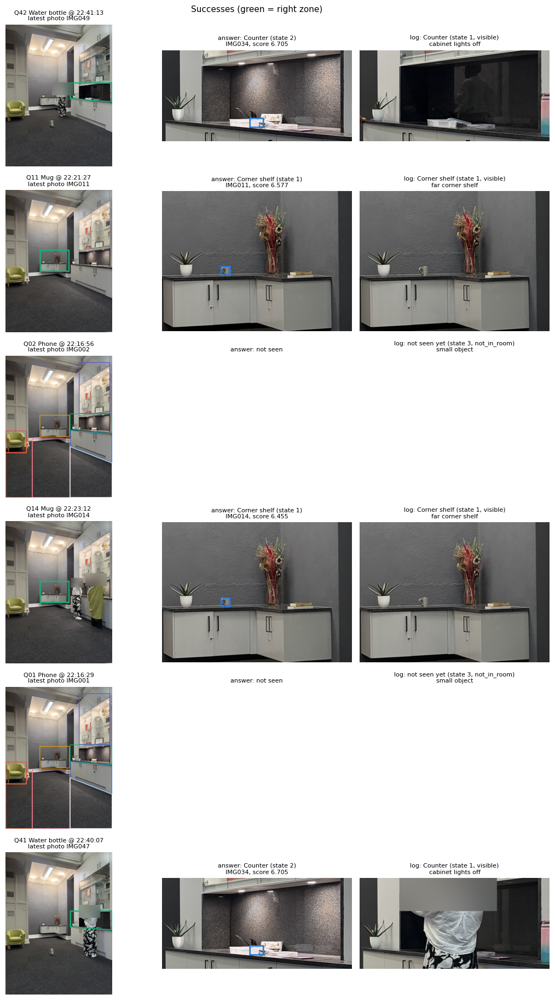

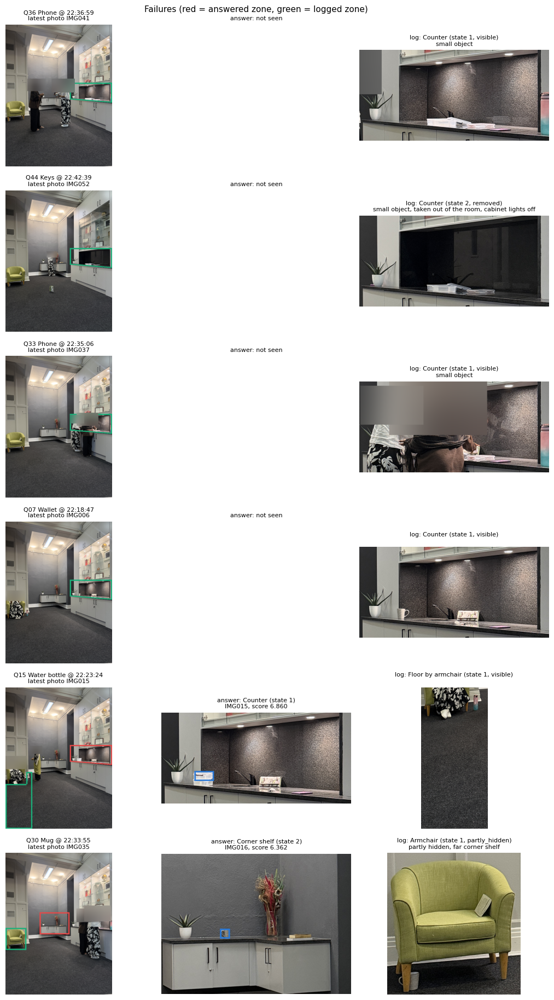

In [32]:
# D6: examples of successes and failures (zone crops as evidence), tagged with likely causes
DARK = {**{f'IMG{n:03d}': 'ceiling light off' for n in (24, 25)},
        **{f'IMG{n:03d}': 'room dark' for n in (44, 45, 46, 57, 58, 59, 60)},
        **{f'IMG{n:03d}': 'cabinet lights off' for n in range(47, 57)}}          # from the S2 Notes tab
SMALL = {'Keys', 'Phone'}

def tags(r):
    t = []
    if r.object in SMALL: t.append('small object')
    if r.gt_now == 'partly_hidden': t.append('partly hidden')
    if r.gt_now == 'blocked': t.append('person in the way')
    if r.gt_now == 'removed': t.append('taken out of the room')
    if r.exp_zone == 3 or r.pred_zone == 3: t.append('far corner shelf')
    if r.pred_zone == 6: t.append('glass shelves (reflections)')
    if FR['S2'].frame[r.now_i] in DARK: t.append(DARK[FR['S2'].frame[r.now_i]])
    return ', '.join(t)

def show_examples(df, title, k=6):
    df = df.head(k)
    if df.empty: print(title, ': none'); return
    fig, axes = plt.subplots(len(df), 3, figsize=(11, 3.1 * len(df)), squeeze=False)
    for ax_row, (_, r) in zip(axes, df.iterrows()):
        img = load_upright(FR['S2'].path[r.now_i], FRAME_MIN_SIDE)
        hl = {}
        if pd.notna(r.exp_zone): hl[int(r.exp_zone)] = '#1baf7a'
        if pd.notna(r.pred_zone): hl[int(r.pred_zone)] = '#e34948' if not r.zone_correct else '#1baf7a'
        ax_row[0].imshow(maybe_blur(draw_zones(img, 'S2', hl), FR['S2'].frame[r.now_i]))
        ax_row[0].set_title(f"{r.qid} {r.object} @ {fmt(r.t)}\nlatest photo {FR['S2'].frame[r.now_i]}", fontsize=8)
        if pd.notna(r.pred_frame_i):
            fz = FR['S2'].frame[int(r.pred_frame_i)]
            ax_row[1].imshow(evidence_crop('S2', int(r.pred_frame_i), int(r.pred_zone), r.pred_box, FROZEN['method']))
            ax_row[1].set_title(f"answer: {ZONE_NAMES[int(r.pred_zone)]} (state {int(r.pred_state)})\n"
                                f"{fz}, score {r.score:.3f}", fontsize=8)
        else: ax_row[1].set_title('answer: not seen', fontsize=8)
        if pd.notna(r.exp_zone):
            ax_row[2].imshow(evidence_crop('S2', r.now_i, int(r.exp_zone)))
        ax_row[2].set_title(f"log: {ZONE_NAMES.get(r.exp_zone, 'not seen yet')} (state {r.exp_state}, {r.gt_now})\n{tags(r)}", fontsize=8)
        for a in ax_row: a.axis('off')
    fig.suptitle(title, fontsize=11); fig.tight_layout(); plt.show()
    EXAMPLE_FIGS.append((title, fig))     # kept for the D7 report

EXAMPLE_FIGS = []
ours = res[res.method == 'ours'].copy()
show_examples(ours[ours.zone_correct].sample(frac=1, random_state=0), 'Successes (green = right zone)')
show_examples(ours[~ours.zone_correct].sample(frac=1, random_state=0), 'Failures (red = answered zone, green = logged zone)')

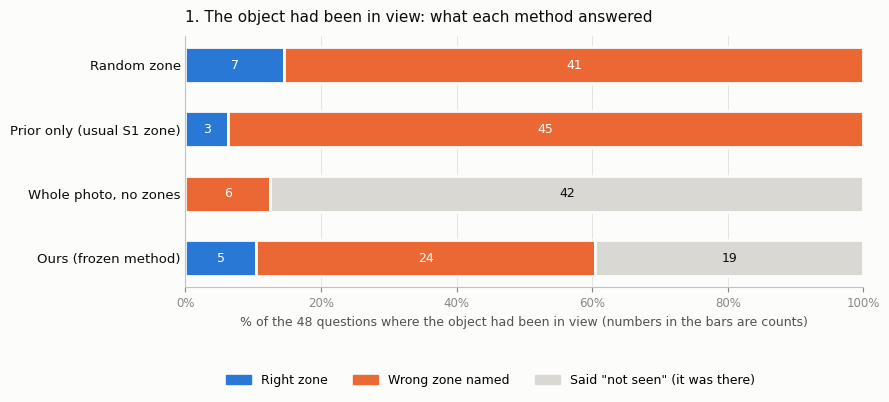

,Right zone,Wrong zone named,"Said ""not seen"" (it was there)",Questions
Method,,,,
Random zone,7,41,0,48
Prior only (usual S1 zone),3,45,0,48
"Whole photo, no zones",0,6,42,48
Ours (frozen method),5,24,19,48



2. The object was never in view: 2 question(s). Random and prior-only always name a zone.


,"Correctly said ""not seen""",Named a zone (sends the user searching),Questions
Method,,,
Random zone,0,2,2
Prior only (usual S1 zone),0,2,2
"Whole photo, no zones",2,0,2
Ours (frozen method),2,0,2


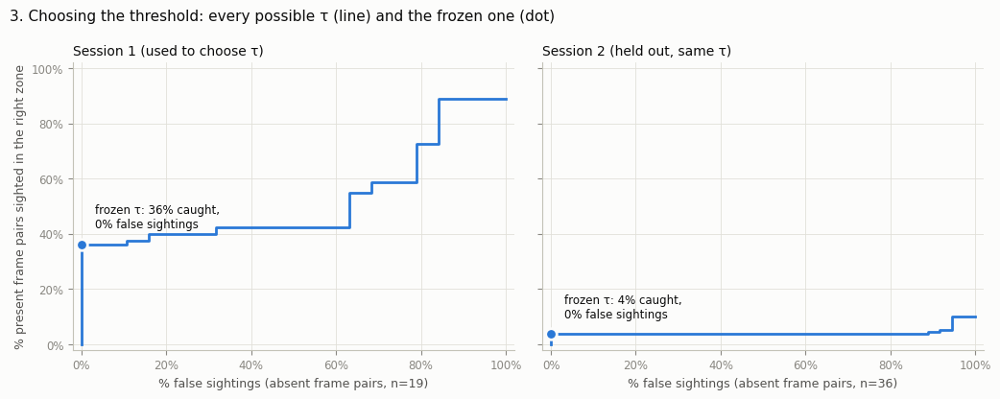

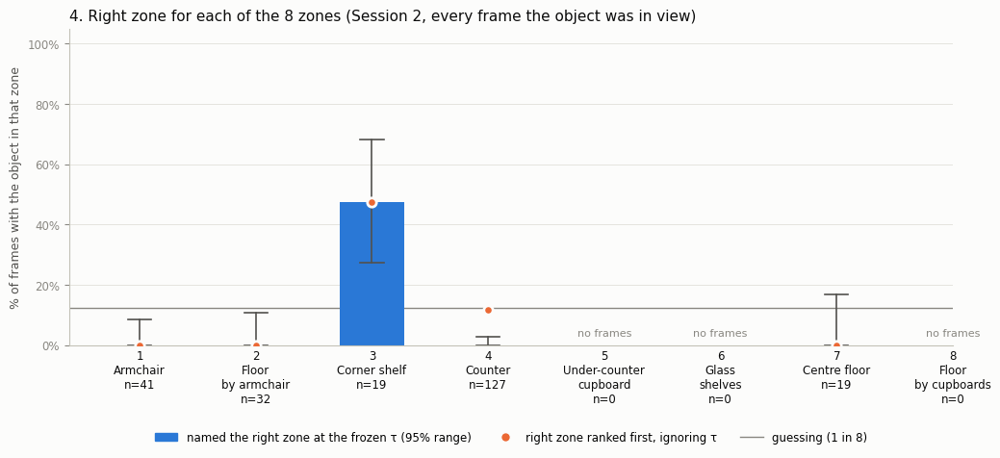

Frames in a row are not independent, so the 95% ranges here are narrower than they should be.


,Present frame pairs,Named at the frozen τ,"Ranked first, ignoring τ"
Zone,,,
1 Armchair,41,0,0
2 Floor by armchair,32,0,0
3 Corner shelf,19,9,9
4 Counter,127,0,15
5 Under-counter cupboard,0,0,0
6 Glass shelves,0,0,0
7 Centre floor,19,0,0
8 Floor by cupboards,0,0,0



Hypotheses (proposal section 3). With so few questions per group, treat these as indications.


,Questions in group,n,Random zone,Prior only (usual S1 zone),"Whole photo, no zones",Ours (frozen method),Ours 95% range,Prediction,Verdict
Hypothesis,,,,,,,,,
H1,"Clear view and usual place: visible, in its us...",3,0/3 = 0%,3/3 = 100%,0/3 = 0%,3/3 = 100%,44-100%,Ours beats guessing by far: its whole 95% rang...,too few questions to tell
H2,"Everything else: small (keys, phone), partly h...",45,7/45 = 16%,0/45 = 0%,0/45 = 0%,2/45 = 4%,1-15%,Guessing matches or beats ours: our 95% range ...,supported



Vanish time: 7 placements end in Session 2. Ours put the last sighting within 1 frame (30 s) of the logged end in 1; the whole-photo baseline in 1.


,Object,Zone,Frames in view,Vanished (log),then,Ours: last sighting,Ours within 1 frame,Whole photo within 1 frame
0,Keys,Counter,IMG005-IMG008,22:20:17,carried,never sighted,False,False
1,Wallet,Counter,IMG037-IMG039,22:36:17,carried,never sighted,False,True
2,Mug,Counter,IMG001-IMG006,22:19:15,carried,never sighted,False,False
3,Mug,Corner shelf,IMG008-IMG016,22:24:24,carried,22:23:53,True,False
4,Phone,Counter,IMG045-IMG047,22:40:23,carried,never sighted,False,False
5,Water bottle,Floor by armchair,IMG001-IMG032,22:32:40,carried,never sighted,False,False
6,Water bottle,Counter,IMG035-IMG049,22:41:25,carried,never sighted,False,False


In [33]:
# D7: PROPOSAL FIGURES AND HYPOTHESES (proposal section 3), from the frozen method's Session 2 answers and scores.
# Analysis only: nothing here changes the frozen method or its threshold.
import base64, io as _io
from IPython.display import display
RESULTS = CACHE.parent / 'results'; RESULTS.mkdir(parents=True, exist_ok=True)
SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
OURS, BASE = '#2a78d6', '#c3c2b7'                           # one highlighted series; baselines in grey
C_RIGHT, C_WRONG, C_MISS = '#2a78d6', '#eb6834', '#d9d8d2'    # right zone / wrong zone named / said "not seen"
METHOD_LABEL = {'ours': 'Ours (frozen method)', 'whole_frame': 'Whole photo, no zones', 'prior_S1': 'Prior only (usual S1 zone)',
                'random': 'Random zone'}
ORDER = ['random', 'prior_S1', 'whole_frame', 'ours']
STATE_LABEL = {1: 'visible now', 2: 'seen earlier', 3: 'not seen yet'}
CHANCE = 1 / 8
FIGS = {}

def pct(k, n): return f'{100 * k / n:.0f}%' if n else 'n/a'

def clean_axes(ax, grid='x'):
    ax.set_facecolor(SURFACE); ax.grid(axis=grid, color=GRID, lw=0.6, zorder=0)
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    for s in ('left', 'bottom'): ax.spines[s].set_color(AXIS)
    ax.tick_params(colors=MUTED, labelsize=8.5)

def fig_png(fig, name=None):
    buf = _io.BytesIO(); fig.savefig(buf, format='png', dpi=130, facecolor=fig.get_facecolor(), bbox_inches='tight')
    if name: (RESULTS / name).write_bytes(buf.getvalue())
    return base64.b64encode(buf.getvalue()).decode()

pct_axis = plt.FuncFormatter(lambda v, _: f'{v:.0f}%')
seen_q = res[res.exp_state.isin([1, 2])].copy()
seen_q['named'] = seen_q.pred_zone.notna(); seen_q['right'] = seen_q.zone_correct.astype(bool)

# ---- figure 1: the object had been in view (proposal figure 1)
P1 = pd.DataFrame([{'Method': METHOD_LABEL[m], 'Right zone': int(g.right.sum()), 'Wrong zone named': int((g.named & ~g.right).sum()),
                    'Said "not seen" (it was there)': int((~g.named).sum()), 'Questions': len(g)}
                   for m in ORDER for g in [seen_q[seen_q.method == m]] if len(g)])
PARTS = [('Right zone', C_RIGHT, 'white'), ('Wrong zone named', C_WRONG, 'white'), ('Said "not seen" (it was there)', C_MISS, INK)]
fig, ax = plt.subplots(figsize=(9, 0.62 * len(P1) + 1.9), facecolor=SURFACE)
y = np.arange(len(P1))[::-1]
for yi, (_, r) in zip(y, P1.iterrows()):
    left = 0.0
    for col, colour, txt in PARTS:
        w = 100 * r[col] / r['Questions']
        if w > 0:
            ax.barh(yi, w, left=left, height=0.56, color=colour, edgecolor=SURFACE, linewidth=2, zorder=2)
            if w >= 6: ax.text(left + w / 2, yi, str(r[col]), ha='center', va='center', fontsize=9, color=txt, zorder=3)
        left += w
clean_axes(ax); ax.set_yticks(y, P1.Method, fontsize=9.5, color=INK); ax.tick_params(axis='y', length=0)
ax.set_xlim(0, 100); ax.xaxis.set_major_formatter(pct_axis)
ax.set_xlabel(f"% of the {int(P1.Questions.max())} questions where the object had been in view (numbers in the bars are counts)",
              fontsize=9, color=INK2)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for _, c, _ in PARTS], labels=[p for p, _, _ in PARTS],
          loc='upper center', bbox_to_anchor=(0.45, -0.3), ncol=3, frameon=False, fontsize=9)
ax.set_title('1. The object had been in view: what each method answered', loc='left', fontsize=11, color=INK, pad=10)
fig.tight_layout(); plt.show(); FIGS['answers'] = fig_png(fig, f'fig1_answers_r{ROUND}.png')
display(P1.set_index('Method'))

# ---- figure 2: the object was never in view (proposal figure 2): too few questions for a chart, so counts
never = res[res.exp_state == 3]
P2 = pd.DataFrame([{'Method': METHOD_LABEL[m], 'Correctly said "not seen"': int(g.pred_zone.isna().sum()),
                    'Named a zone (sends the user searching)': int(g.pred_zone.notna().sum()), 'Questions': len(g)}
                   for m in ORDER for g in [never[never.method == m]] if len(g)])
print(f'\n2. The object was never in view: {len(never) // max(1, len(ORDER))} question(s). Random and prior-only always name a zone.')
display(P2.set_index('Method'))

# ---- figure 3: choosing the threshold (proposal figure 3), Session 1 and the same tau on Session 2
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), sharey=True, facecolor=SURFACE)
TH = {}
for ax, s in zip(axes, ('S1', 'S2')):
    best, arg, pres, absn, zt = pair_arrays(SCORES[s], GT[s], FROZEN)
    ts = np.r_[best.min() - 1e-3, np.unique(best), best.max() + 1e-3]
    cur = np.array([[rates_at(t, best, arg, pres, absn, zt)[q] for q in ('false_sighting_rate', 'right_zone_rate')] for t in ts])
    r = rates_at(TAU, best, arg, pres, absn, zt); TH[s] = r
    clean_axes(ax, grid='both')
    ax.plot(100 * cur[:, 0], 100 * cur[:, 1], color=OURS, lw=2, zorder=2)
    ax.scatter([100 * r['false_sighting_rate']], [100 * r['right_zone_rate']], s=70, color=OURS, edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.annotate(f"frozen τ: {100 * r['right_zone_rate']:.0f}% caught,\n{100 * r['false_sighting_rate']:.0f}% false sightings",
                (100 * r['false_sighting_rate'], 100 * r['right_zone_rate']), xytext=(10, 10), textcoords='offset points',
                fontsize=8.5, color=INK, va='bottom')
    ax.set_xlim(-2, 102); ax.set_ylim(-2, 102); ax.xaxis.set_major_formatter(pct_axis); ax.yaxis.set_major_formatter(pct_axis)
    ax.set_xlabel(f'% false sightings (absent frame pairs, n={int(absn.sum())})', fontsize=9, color=INK2)
    ax.set_title('Session 1 (used to choose τ)' if s == 'S1' else 'Session 2 (held out, same τ)', loc='left', fontsize=10, color=INK)
axes[0].set_ylabel('% present frame pairs sighted in the right zone', fontsize=9, color=INK2)
fig.suptitle('3. Choosing the threshold: every possible τ (line) and the frozen one (dot)', x=0.01, ha='left', fontsize=11, color=INK)
fig.tight_layout(); plt.show(); FIGS['threshold'] = fig_png(fig, f'fig3_threshold_r{ROUND}.png')

# ---- figure 4: right zone for each of the 8 zones (proposal's per-zone chart), all Session 2 frame pairs
best2, arg2, pres2, absn2, zt2 = pair_arrays(SCORES['S2'], GT['S2'], FROZEN)
PZ = []
for z in range(1, 9):
    mz = pres2 & (zt2 == z)
    PZ.append({'Zone': f'{z} {ZONE_NAMES[z]}', 'Present frame pairs': int(mz.sum()),
               'Named at the frozen τ': int(((best2 >= TAU) & (arg2 == zt2))[mz].sum()),
               'Ranked first, ignoring τ': int((arg2 == zt2)[mz].sum())})
PZ = pd.DataFrame(PZ)
fig, ax = plt.subplots(figsize=(10.5, 5.0), facecolor=SURFACE); clean_axes(ax, grid='y')
x = np.arange(1, 9)
for xi, r in zip(x, PZ.itertuples()):
    n = r[2]
    if n == 0:
        ax.text(xi, 3, 'no frames', ha='center', fontsize=8, color=MUTED); continue
    k1, k2 = r[3], r[4]; lo, hi = wilson(k1, n)
    ax.bar(xi, 100 * k1 / n, width=0.56, color=OURS, zorder=2)
    ax.plot([xi, xi], [100 * lo, 100 * hi], color=INK2, lw=1.2, zorder=3)
    for v in (lo, hi): ax.plot([xi - 0.1, xi + 0.1], [100 * v] * 2, color=INK2, lw=1.2, zorder=3)
    ax.scatter([xi], [100 * k2 / n], s=46, color=C_WRONG, edgecolor=SURFACE, linewidth=2, zorder=4)
ax.axhline(100 * CHANCE, color=MUTED, lw=1, zorder=1)
ax.set_xticks(x, [f"{z}\n{ZONE_NAMES[z].replace(' ', chr(10), 1) if len(ZONE_NAMES[z]) > 12 else ZONE_NAMES[z]}\nn={PZ['Present frame pairs'][z - 1]}"
                  for z in x], fontsize=8.5, color=INK)
ax.set_ylim(0, 105); ax.yaxis.set_major_formatter(pct_axis); ax.tick_params(axis='x', length=0)
ax.set_ylabel('% of frames with the object in that zone', fontsize=9, color=INK2)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=OURS),
                   plt.Line2D([], [], marker='o', ls='', color=C_WRONG, markeredgecolor=SURFACE, markersize=7),
                   plt.Line2D([], [], color=MUTED, lw=1)],
          labels=['named the right zone at the frozen τ (95% range)', 'right zone ranked first, ignoring τ', 'guessing (1 in 8)'],
          loc='upper center', bbox_to_anchor=(0.5, -0.24), ncol=3, frameon=False, fontsize=8.5)
ax.set_title('4. Right zone for each of the 8 zones (Session 2, every frame the object was in view)', loc='left', fontsize=11, color=INK)
fig.tight_layout(); plt.show(); FIGS['zones'] = fig_png(fig, f'fig4_zones_r{ROUND}.png')
print('Frames in a row are not independent, so the 95% ranges here are narrower than they should be.')
display(PZ.set_index('Zone'))

# ---- H1 / H2 (proposal hypotheses), on the seen-before questions
usual = {o: int(z) for o, z in cfg['usual_zone_S1'].items()}
def hgroup(r):
    clear_usual = (r.gt_now == 'visible' and int(r.exp_zone) == usual[r.object] and r.object not in ('Keys', 'Phone')
                   and int(r.exp_zone) != 3)
    return 'H1' if clear_usual else 'H2'
seen_q['group'] = [hgroup(r) for r in seen_q.itertuples()]
HT = []
for g_, desc, claim in (('H1', 'Clear view and usual place: visible, in its usual Session 1 zone, not keys/phone, not the far shelf',
                         'Ours beats guessing by far: its whole 95% range is above 12.5%'),
                        ('H2', 'Everything else: small (keys, phone), partly hidden or blocked, far corner shelf, or an unusual zone',
                         'Guessing matches or beats ours: our 95% range reaches down to 12.5%')):
    gq = seen_q[seen_q.group == g_]; n = int((gq.method == 'ours').sum())
    k = {m: int(gq[gq.method == m].right.sum()) for m in ORDER}
    lo, hi = wilson(k['ours'], n) if n else (np.nan, np.nan)
    ok = (lo > CHANCE) if g_ == 'H1' else (lo <= CHANCE)
    HT.append({'Hypothesis': g_, 'Questions in group': desc, 'n': n,
               **{METHOD_LABEL[m]: f"{k[m]}/{n} = {pct(k[m], n)}" for m in ORDER},
               'Ours 95% range': f'{100 * lo:.0f}-{100 * hi:.0f}%' if n else '-', 'Prediction': claim,
               'Verdict': ('too few questions to tell' if n < 5 else 'supported' if ok else 'not supported')})
HT = pd.DataFrame(HT)
print('\nHypotheses (proposal section 3). With so few questions per group, treat these as indications.')
display(HT.set_index('Hypothesis'))

# ---- when it vanished (proposal: the frame after the last sighting gives the vanish time), Session 2
st2, zn2 = GT['S2']['state'], GT['S2']['zone']
bestS, zoneS = SCORES['S2'].max(1), zone_choice(SCORES['S2'], FROZEN) + 1
VAN = []
for k, o in enumerate(OBJECTS):
    pres_k = np.isin(st2[:, k], PRESENT); i = 0
    while i < len(st2):
        if not pres_k[i]: i += 1; continue
        j = i
        while j + 1 < len(st2) and pres_k[j + 1] and zn2[j + 1, k] == zn2[i, k]: j += 1
        if j + 1 < len(st2) and st2[j + 1, k] != 'blocked':          # the placement ends (a person in the way is not a vanish)
            hit = np.flatnonzero((bestS[i:j + 1, k] >= TAU) & (zoneS[i:j + 1, k] == zn2[i, k])) + i
            whit = np.flatnonzero(WSCORES['S2'][i:j + 1, k] >= TAU_W) + i
            VAN.append({'Object': o, 'Zone': ZONE_NAMES[int(zn2[i, k])], 'Frames in view': f'{FR["S2"].frame[i]}-{FR["S2"].frame[j]}',
                        'Vanished (log)': fmt(FR['S2'].time[j + 1]), 'then': st2[j + 1, k].replace('_', ' '),
                        'Ours: last sighting': fmt(FR['S2'].time[hit[-1]]) if len(hit) else 'never sighted',
                        'Ours within 1 frame': bool(len(hit) and hit[-1] >= j - 1),
                        'Whole photo within 1 frame': bool(len(whit) and whit[-1] >= j - 1)})
        i = j + 1
VAN = pd.DataFrame(VAN)
if len(VAN):
    print(f"\nVanish time: {len(VAN)} placements end in Session 2. Ours put the last sighting within 1 frame (30 s) of the logged "
          f"end in {int(VAN['Ours within 1 frame'].sum())}; the whole-photo baseline in {int(VAN['Whole photo within 1 frame'].sum())}.")
    display(VAN)


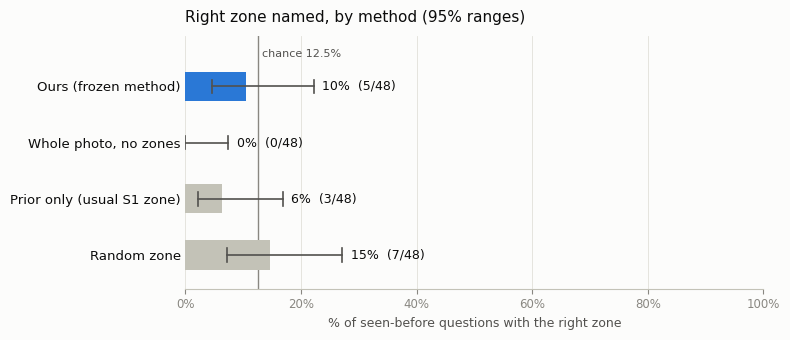

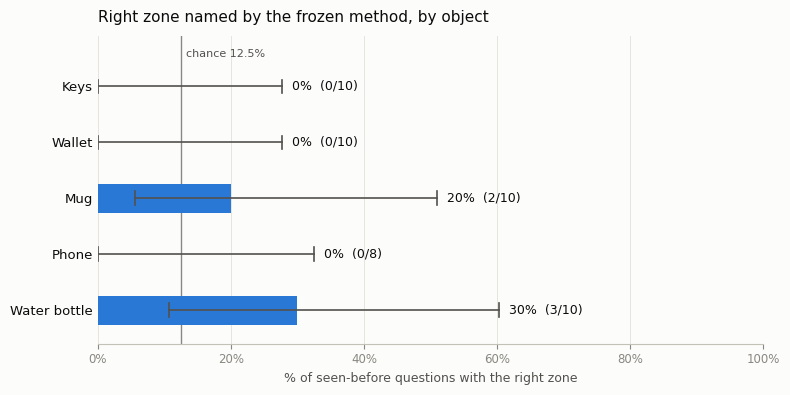


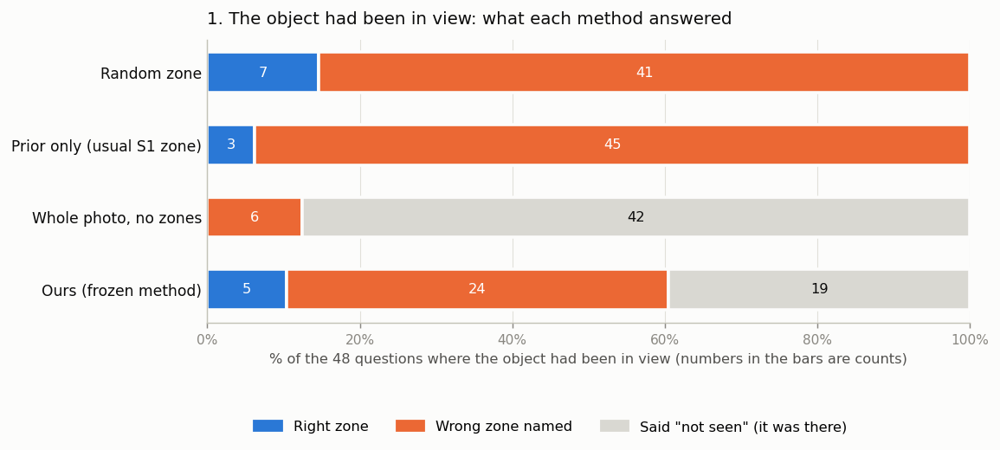
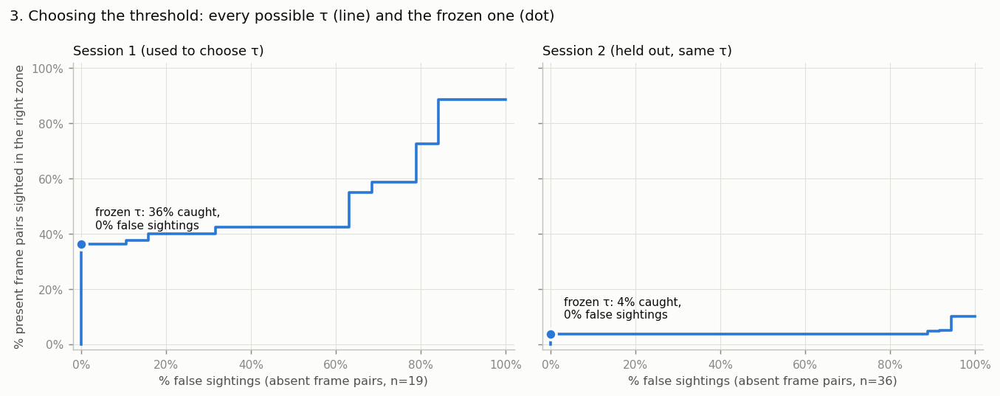
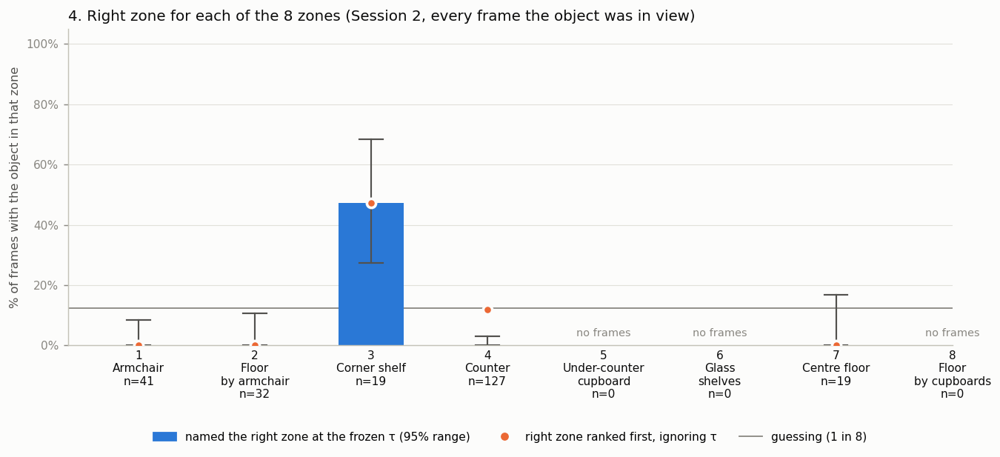
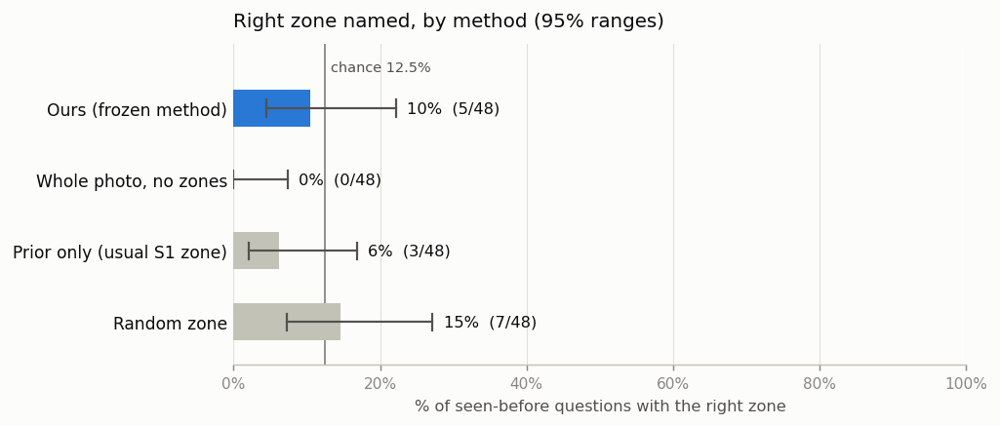
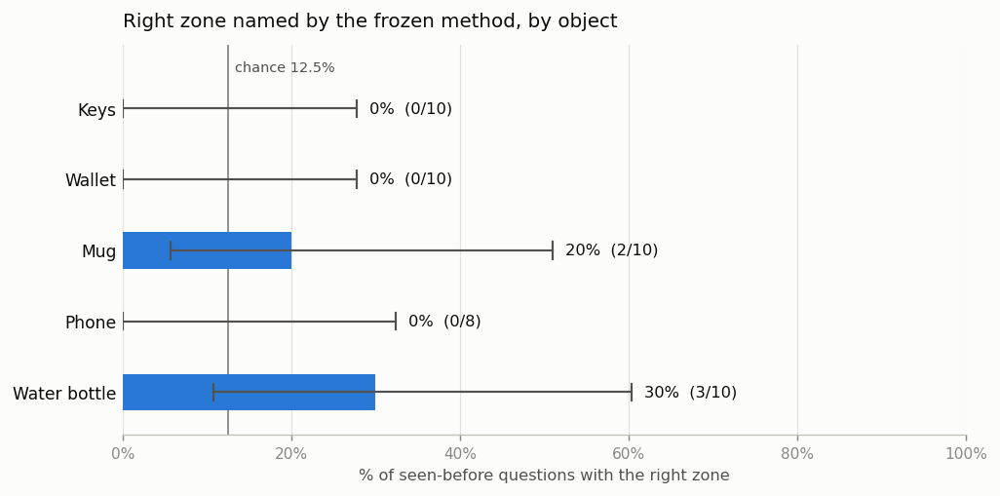
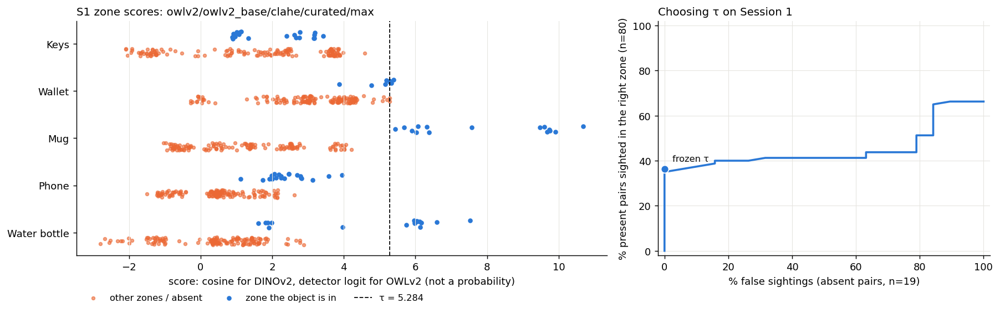
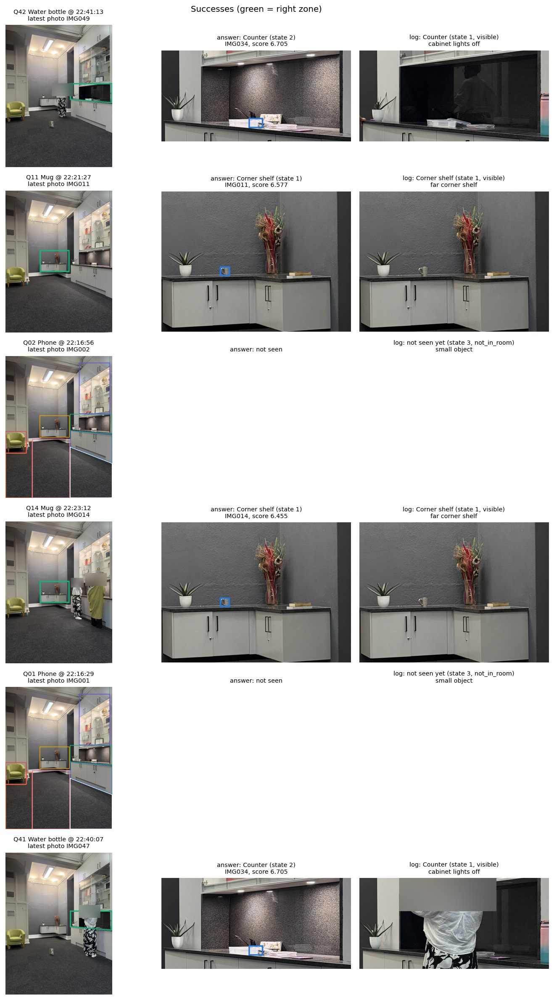
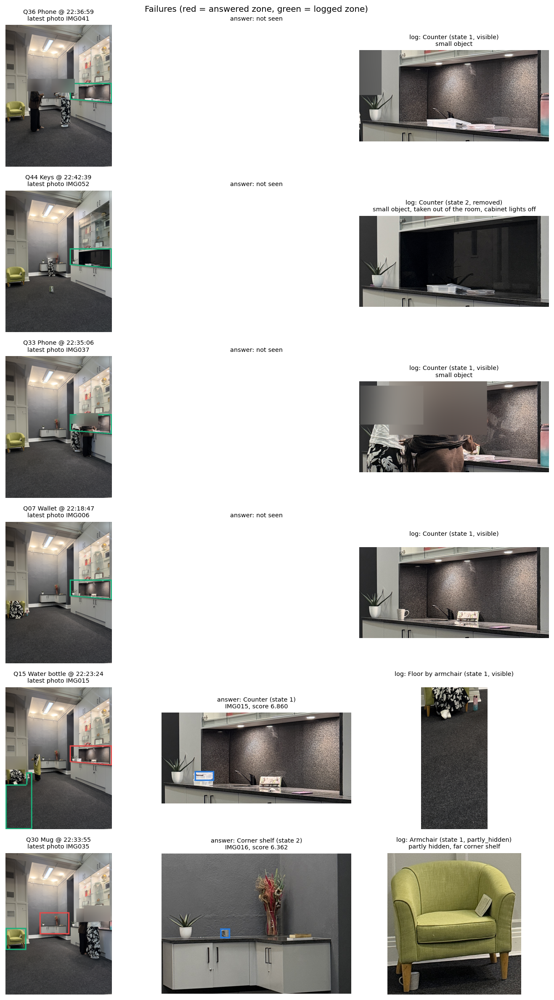


Saved to /kaggle/working/results: report_r3.html (open in a browser), figures 1-4 and charts as PNG, CSVs for every table, frozen_config_r3.json. On Kaggle: Output panel -> results.


In [34]:
# D8: RESULTS REPORT. A readable summary here, and the same report as one HTML file (plus PNG charts and CSVs) in results/.
import html as _html
from IPython.display import HTML as _HTML
INCLUDE_EXAMPLES = True   # put the D6 example photos in the report (heads blurred as set in A5); False = charts and tables only

def method_rows(r):
    """One row per method: right-zone accuracy on seen-before questions (95% Wilson range) and the other counts."""
    out = []
    for m in ORDER[::-1]:
        g = r[r.method == m]
        if g.empty: continue
        seen = g[g.exp_state.isin([1, 2])]; k, n = int(seen.zone_correct.sum()), len(seen); lo, hi = wilson(k, n)
        ka = int(g.zone_correct.sum())
        row = {'method': m, 'Method': METHOD_LABEL[m], 'k': k, 'n': n, 'acc': k / n if n else np.nan, 'lo': lo, 'hi': hi,
               'Right zone (object seen before)': f'{k}/{n} = {pct(k, n)}', '95% range': f'{100 * lo:.0f}-{100 * hi:.0f}%',
               'All answers right': f'{ka}/{len(g)} = {pct(ka, len(g))}'}
        if m in ('ours', 'whole_frame'):
            nf, nm = int((g.exp_state != 1).sum()), int((g.exp_state == 1).sum())
            row.update({'False sightings': f'{int(g.false_sighting.sum())}/{nf}',
                        'Missed (visible but not found)': f'{int(g.missed.sum())}/{nm}',
                        'Right state': f'{int((g.pred_state == g.exp_state).sum())}/{len(g)}'})
        out.append(row)
    return pd.DataFrame(out)

def bar_chart(labels, k, n, colours, title, xlabel):
    """Horizontal bars of k/n with 95% Wilson whiskers, a labelled chance line, and the value at each bar end."""
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(labels) + 1.3), facecolor=SURFACE); clean_axes(ax)
    y = np.arange(len(labels))[::-1]
    for yi, kk, nn, col in zip(y, k, n, colours):
        acc = kk / nn if nn else 0; lo, hi = wilson(kk, nn) if nn else (0, 0)
        ax.barh(yi, 100 * acc, height=0.52, color=col, zorder=2)
        ax.plot([100 * lo, 100 * hi], [yi, yi], color=INK2, lw=1.2, zorder=3)
        for v in (lo, hi): ax.plot([100 * v] * 2, [yi - 0.12, yi + 0.12], color=INK2, lw=1.2, zorder=3)
        ax.text(min(100 * hi + 1.5, 86), yi, f'{100 * acc:.0f}%  ({kk}/{nn})', va='center', fontsize=9, color=INK)
    ax.axvline(100 * CHANCE, color=MUTED, lw=1, zorder=1)
    ax.text(100 * CHANCE + 0.8, y.max() + 0.48, 'chance 12.5%', fontsize=8, color=INK2, va='bottom')
    ax.set_yticks(y, labels, fontsize=9.5, color=INK); ax.tick_params(axis='y', length=0)
    ax.set_xlim(0, 100); ax.set_ylim(-0.6, y.max() + 0.9); ax.xaxis.set_major_formatter(pct_axis)
    ax.set_xlabel(xlabel, fontsize=9, color=INK2); ax.spines['left'].set_visible(False)
    ax.set_title(title, loc='left', fontsize=11, color=INK, pad=10)
    fig.tight_layout()
    return fig

def round_rows():
    """Ours on Session 2 for every round whose results exist in this cache."""
    rows = []
    for rnd in range(1, 10):
        f = CACHE / ('s2_results.csv' if rnd == 1 else f's2_results_r{rnd}.csv')
        c = CACHE / ('frozen_config.json' if rnd == 1 else f'frozen_config_r{rnd}.json')
        if not f.exists(): continue
        m = method_rows(pd.read_csv(f)).set_index('method').loc['ours']
        rows.append({'Round': rnd, 'Frozen method': describe_spec(spec_of(json.loads(c.read_text()))) if c.exists() else '?',
                     'Right zone (object seen before)': m['Right zone (object seen before)'], '95% range': m['95% range'],
                     'All answers right': m['All answers right'], 'False sightings': m['False sightings'],
                     'Missed (visible but not found)': m['Missed (visible but not found)']})
    return pd.DataFrame(rows)

def zone_name(z): return ZONE_NAMES.get(int(z), '?') if pd.notna(z) else '-'

# ---- numbers and the headline
MT = method_rows(res)
ours_row = MT.set_index('method').loc['ours']
best_base = MT[MT.method.isin(['prior_S1', 'random', 'whole_frame'])].sort_values('acc').iloc[-1]
o = res[res.method == 'ours'].copy()
o1 = P1.set_index('Method').loc[METHOD_LABEL['ours']]
n_named = int(o1['Right zone'] + o1['Wrong zone named']); n_wrong = int(o1['Questions'] - o1['Right zone'])
n_miss = int(o1['Said "not seen" (it was there)'])
verdict = ('clearly better than guessing (its whole 95% range is above chance)' if ours_row.lo > CHANCE else
           'above chance, but its 95% range still includes chance, so this could be luck' if ours_row.acc > CHANCE else
           'no better than guessing')
HEADLINE = (f"On the {ours_row.n} Session 2 questions where the object had already been seen, the frozen method named the right "
            f"zone {ours_row.k} times ({pct(ours_row.k, ours_row.n)}; 95% range {ours_row['95% range']}). That is {verdict}. "
            f"Random guessing is right 12.5% of the time; the best baseline here, {best_base.Method.lower()}, got "
            f"{pct(best_base.k, best_base.n)}. When it did name a zone, it was right {int(o1['Right zone'])} of {n_named} times "
            f"({pct(int(o1['Right zone']), n_named)}).")
if n_wrong and n_miss / n_wrong >= 0.6:
    HEADLINE += (f" Most of its wrong answers ({n_miss} of {n_wrong}) were \"not seen\" while the object was there: the "
                 f"threshold frozen on Session 1 is the main limit, more than the zone it picks.")

per_obj = []
for ob in OBJECTS:
    row = {'Object': ob}
    for m in ORDER[::-1]:
        g = res[(res.method == m) & (res.object == ob) & res.exp_state.isin([1, 2])]
        row[METHOD_LABEL[m]] = f'{int(g.zone_correct.sum())}/{len(g)} = {pct(int(g.zone_correct.sum()), len(g))}'
    per_obj.append(row)
PER_OBJ = pd.DataFrame(per_obj)
STATES = pd.crosstab(o.exp_state.map(STATE_LABEL), o.pred_state.map(STATE_LABEL).fillna('not seen yet'))
STATES = STATES.reindex(index=[STATE_LABEL[s] for s in (1, 2, 3) if STATE_LABEL[s] in STATES.index],
                        columns=[STATE_LABEL[s] for s in (1, 2, 3)], fill_value=0)
STATES.index.name, STATES.columns.name = 'Log says', 'Answer said'
ANSWERS = pd.DataFrame({
    'Question': o.qid, 'Object': o.object, 'Asked at': pd.to_datetime(o.t).dt.strftime('%H:%M:%S'),
    'Log says': [f'{STATE_LABEL[s]}' + (f', {zone_name(z)}' if s != 3 else '') for s, z in zip(o.exp_state, o.exp_zone)],
    'Answer': [f'{STATE_LABEL[int(s)]}' + (f', {zone_name(z)}' if pd.notna(z) else '') if pd.notna(s) else '-'
               for s, z in zip(o.pred_state, o.pred_zone)],
    'Right?': np.where(o.zone_correct, '✓ right', '✗ wrong'),
    'Score': [f'{v:.3f}' if pd.notna(v) else '' for v in o.score]}).reset_index(drop=True)
ROUNDS = round_rows()

f1 = bar_chart(list(MT.Method), list(MT.k), list(MT.n), [OURS if m == 'ours' else BASE for m in MT.method],
               'Right zone named, by method (95% ranges)', '% of seen-before questions with the right zone')
g_obj = [o[(o.object == ob) & o.exp_state.isin([1, 2])] for ob in OBJECTS]
f2 = bar_chart(OBJECTS, [int(g.zone_correct.sum()) for g in g_obj], [len(g) for g in g_obj], [OURS] * len(OBJECTS),
               'Right zone named by the frozen method, by object', '% of seen-before questions with the right zone')
plt.show()
FIGS['methods'], FIGS['objects'] = fig_png(f1, f'chart_methods_r{ROUND}.png'), fig_png(f2, f'chart_objects_r{ROUND}.png')
if 'C3_FIG' in globals(): FIGS['s1_choice'] = fig_png(C3_FIG, f'chart_session1_choice_r{ROUND}.png')

# ---- files to download
MT.drop(columns=['method', 'k', 'n', 'acc', 'lo', 'hi']).to_csv(RESULTS / f'summary_r{ROUND}.csv', index=False)
ANSWERS.to_csv(RESULTS / f'answers_r{ROUND}.csv', index=False)
PER_OBJ.to_csv(RESULTS / f'by_object_r{ROUND}.csv', index=False)
P1.to_csv(RESULTS / f'fig1_answers_r{ROUND}.csv', index=False); P2.to_csv(RESULTS / f'fig2_never_in_view_r{ROUND}.csv', index=False)
PZ.to_csv(RESULTS / f'fig4_zones_r{ROUND}.csv', index=False); HT.to_csv(RESULTS / f'hypotheses_r{ROUND}.csv', index=False)
VAN.to_csv(RESULTS / f'vanish_r{ROUND}.csv', index=False)
if len(ROUNDS): ROUNDS.to_csv(RESULTS / 'rounds_compared.csv', index=False)
(RESULTS / round_file('frozen_config.json').name).write_text(round_file('frozen_config.json').read_text())

# ---- the report (shown here and saved as HTML)
def table(df, index=False): return df.to_html(index=index, classes='t', border=0, escape=True)
def img(key, alt): return f'<img src="data:image/png;base64,{FIGS[key]}" alt="{_html.escape(alt)}">' if key in FIGS else ''

tiles = [('Right zone named', pct(ours_row.k, ours_row.n), f"{ours_row.k}/{ours_row.n} seen-before questions; chance 12.5%"),
         ('Right when it named a zone', pct(int(o1['Right zone']), n_named), f"{int(o1['Right zone'])}/{n_named} zones named"),
         ('Missed', ours_row['Missed (visible but not found)'], 'visible in the latest photo but not found'),
         ('False sightings', ours_row['False sightings'], 'said "visible now" when it was not')]
examples = ''.join(f'<h3>{_html.escape(t)}</h3><img src="data:image/png;base64,{fig_png(f)}" alt="{_html.escape(t)}">'
                   for t, f in globals().get('EXAMPLE_FIGS', [])) if INCLUDE_EXAMPLES else ''
STYLE = """<style>
.pf-report{--surface:#fcfcfb;--ink:#0b0b0b;--ink2:#52514e;--muted:#898781;--line:#e1e0d9;--accent:#2a78d6;--tint:#e6effa;
 font-family:system-ui,-apple-system,"Segoe UI",sans-serif;color:var(--ink);background:var(--surface);max-width:1000px;padding:8px 4px;
 line-height:1.45;color-scheme:light}
.pf-report h2{font-size:20px;margin:4px 0 6px}.pf-report h3{font-size:15px;margin:28px 0 6px}
.pf-report .lead{font-size:15px;margin:0 0 14px;max-width:840px}.pf-report .note{color:var(--ink2);font-size:12.5px;margin:4px 0 10px}
.pf-report .tiles{display:flex;flex-wrap:wrap;gap:10px;margin:10px 0 6px}
.pf-report .tile{border:1px solid var(--line);border-radius:8px;padding:10px 14px;min-width:160px;flex:1}
.pf-report .tile b{display:block;font-size:26px;font-weight:600}.pf-report .tile span{color:var(--ink2);font-size:12px}
.pf-report .tile.main{border-color:var(--accent);background:var(--tint)}
.pf-report table.t{border-collapse:collapse;font-size:12.5px;margin:6px 0 4px;font-variant-numeric:tabular-nums}
.pf-report table.t th{text-align:left;color:var(--ink2);font-weight:600;border-bottom:1px solid var(--muted);padding:5px 10px 5px 0}
.pf-report table.t td{border-bottom:1px solid var(--line);padding:4px 10px 4px 0;vertical-align:top}
.pf-report img{max-width:100%;height:auto;border:1px solid var(--line);border-radius:6px;margin:4px 0}
</style>"""
spec_now = spec_of(cfg)
BODY = f"""<div class="pf-report">
<h2>Pause &amp; Find results: round {ROUND}</h2>
<p class="note">Frozen method: {_html.escape(describe_spec(spec_now))} | threshold τ = {cfg['tau_zone']:.3f} | frozen {cfg['frozen_at']} |
{_html.escape(cfg.get('chosen_by', ''))} | {len(queries)} Session 2 questions</p>
<p class="lead">{_html.escape(HEADLINE)}</p>
<div class="tiles">{''.join(f'<div class="tile{" main" if i == 0 else ""}"><span>{a}</span><b>{b}</b><span>{_html.escape(c)}</span></div>' for i, (a, b, c) in enumerate(tiles))}</div>
<h3>1. The object had been in view</h3>{img('answers', 'Answers by method')}
<p class="note">Blue = right zone; orange = a zone was named but it was the wrong one; grey = said "not seen" although the object was there. Random and prior-only always name a zone.</p>
{table(P1)}
<h3>2. The object was never in view</h3>
<p class="note">The right answer is "not seen"; naming a zone sends the user searching. Only {len(never) // max(1, len(ORDER))} such question(s), so no chart.</p>{table(P2)}
<h3>3. Choosing the threshold</h3>{img('threshold', 'Threshold curves')}
<p class="note">Each point on a line is one possible threshold τ; the dot is the τ frozen on Session 1. If the Session 2 dot sits far left and low,
the frozen τ was too strict for Session 2. Analysis only: τ was not changed.</p>
<h3>4. Right zone for each of the 8 zones</h3>{img('zones', 'Right zone by zone')}
<p class="note">Bars: right zone named at the frozen τ. Dots: right zone ranked first if the threshold is ignored, which shows whether
the zone choice or the threshold is the problem. Frames in a row are not independent, so the 95% ranges are too narrow.</p>{table(PZ)}
<h3>Hypotheses H1 and H2</h3>{table(HT)}
<h3>When it vanished</h3>
<p class="note">For each placement that ends in Session 2: is the last sighting in that zone within one frame (30 s) of the logged end?</p>
{table(VAN) if len(VAN) else '<p class="note">No placement ends in Session 2.</p>'}
<h3>Right zone by method, with 95% ranges</h3>{img('methods', 'Right zone by method')}
{table(MT.drop(columns=['method', 'k', 'n', 'acc', 'lo', 'hi']).fillna(''))}
<h3>Right zone by object</h3>{img('objects', 'Right zone by object')}{table(PER_OBJ)}
<h3>What kind of answer it gave</h3>
<p class="note">Rows: the placement log at the question time. Columns: the frozen method's answer. The diagonal is the right kind of answer.</p>
{table(STATES, index=True)}
{f'<h3>Rounds compared</h3>' + table(ROUNDS) if len(ROUNDS) else ''}
{f'<h3>How the method was chosen (Session 1 only)</h3>' + img('s1_choice', 'Session 1 choice') if 's1_choice' in FIGS else ''}
{('<p class="note">Top settings from C2:</p>' + table(C2_VIEW.head(8), index=True)) if 'C2_VIEW' in globals() else ''}
<h3>Every question</h3>{table(ANSWERS)}
{('<h3>Examples</h3><p class="note">Photos with heads blurred (A5). Green = logged zone; red = a wrong answer.</p>' + examples) if examples else ''}
<p class="note">Runtime: {ENV}, {DEVICE}; one frame {S2_TIMING['decode_s_per_frame']:.2f} s to decode, {S2_TIMING['encode_s_per_frame']:.2f} s in the model.
A score is not a probability.</p></div>"""
report_path = RESULTS / f'report_r{ROUND}.html'
report_path.write_text(f'<!doctype html><html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">'
                       f'<title>Pause and Find results</title>{STYLE}</head><body style="margin:16px;background:#fcfcfb">{BODY}</body></html>',
                       encoding='utf-8')
display(_HTML(STYLE + BODY))
print(f'\nSaved to {RESULTS}: {report_path.name} (open in a browser), figures 1-4 and charts as PNG, CSVs for every table, '
      f'{round_file("frozen_config.json").name}. On Kaggle: Output panel -> results.')


## Part E: Pause & Find demo
1. **Pick random moment** pauses Session 2 at a random time.
2. Choose an object and press **Where was it last seen?** The system answers using only photos up to that moment. It shows the answer, the time and the evidence crop, and speaks the answer. On Colab the voice is your **browser's** text-to-speech. On Kaggle it is an audio clip from Google's online text-to-speech (gTTS); press play if your browser blocks autoplay.
3. **Reveal placement log** shows the logged state *after* the answer.

**Where things run:** the encoder ran in this cloud notebook session (Kaggle or Colab), and the speech comes from the browser or from Google's TTS service. This demo does **not** show that the system runs offline on a phone. That needs the separate test at the end of the notebook.

**Privacy:** most Session 2 photos show people. If a Roboflow COCO export of Session 2 is in `DATA_ROOT`, everything this notebook displays has people's heads blurred: the top of each person box, so it works whichever way a person faces. Set `BLUR_PART = 'body'` in A5 to blur whole bodies instead. The boxes are used only for display, after the answer. A person in a frame that has no person box in the export is not blurred, so check the export covers every frame with people in it. Without an export, a warning is printed.

In [35]:
# E1: display helpers: evidence figure and speech (person blur is set up in A5)
SPEECH = 'auto'   # 'auto': Colab -> browser voice; Kaggle/other -> gTTS audio clip. Or 'browser', 'gtts', 'off'.
def speak(text):
    from IPython.display import Javascript, Audio, display as _d
    mode = SPEECH if SPEECH != 'auto' else ('browser' if IN_COLAB else 'gtts')
    if mode == 'off': return
    if mode == 'gtts':     # Google's online text-to-speech (needs Internet); plays as an audio clip
        try:
            import io
            from gtts import gTTS
            buf = io.BytesIO(); gTTS(text, lang='en').write_to_fp(buf)
            _d(Audio(buf.getvalue(), autoplay=True)); return
        except Exception as e:
            print(f'(gTTS speech unavailable: {type(e).__name__}; trying the browser voice)')
    js = f"window.speechSynthesis.cancel(); window.speechSynthesis.speak(new SpeechSynthesisUtterance({json.dumps(text)}));"
    if IN_COLAB:
        from google.colab import output; output.eval_js(js, ignore_result=True)
    else:
        _d(Javascript(js))

if not IN_COLAB and importlib.util.find_spec('gtts') is None:
    # --no-deps: gTTS pins an old 'click' (only for its command-line tool), and a normal install would downgrade the
    # click that Kaggle's huggingface-hub and others need. Speaking only needs 'requests', which is already installed.
    r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', 'gTTS'], capture_output=True, text=True, timeout=120)
    importlib.invalidate_caches()
    if r.returncode != 0 or importlib.util.find_spec('gtts') is None:
        print('could not install gTTS (Internet off?); the demo will print answers and try the browser voice.',
              (r.stderr or '').strip().splitlines()[-1:] )

t_first, t_last = FR['S2'].time.iloc[0], FR['S2'].time.iloc[-1]   # demo range (used by E2 and E3)
demo_rng = np.random.default_rng()

def evidence_figure(sess, t, obj, a):
    h = history(sess, t); now = h['n'] - 1
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
    if now >= 0:
        img = load_upright(FR[sess].path[now], FRAME_MIN_SIDE)
        hl = {a['zone']: '#2a78d6'} if a['state'] == 1 else None
        axes[0].imshow(maybe_blur(draw_zones(img, sess, hl), FR[sess].frame[now]))
        axes[0].set_title(f"latest photo at or before {fmt(t)}: {FR[sess].frame[now]} ({fmt(h['times'][now])})", fontsize=9)
    if a['frame_i'] is not None:
        f = FR[sess].frame[a['frame_i']]
        axes[1].imshow(evidence_crop(sess, a['frame_i'], a['zone'], a.get('box'), FROZEN['method']))
        axes[1].set_title(f"evidence: {ZONE_NAMES[a['zone']]} crop, {f} at {fmt(h['times'][a['frame_i']])}\n"
                          f"score {a['score']:.3f} (threshold {TAU:.3f}; not a probability)", fontsize=9)
    else:
        axes[1].text(0.5, 0.5, 'no matching crop so far', ha='center', va='center')
    for ax in axes: ax.axis('off')
    fig.tight_layout(); plt.show()

In [36]:
# E2: the interactive demo. If the buttons do nothing in your editor, use E3 below.
import ipywidgets as W
from IPython.display import display, clear_output
state = {'t': None, 'answered': None}

pick_btn = W.Button(description='Pick random moment', button_style='info', layout=W.Layout(width='180px'))
obj_dd = W.Dropdown(options=OBJECTS, description='Object:')
ask_btn = W.Button(description='Where was it last seen?', button_style='primary', layout=W.Layout(width='200px'), disabled=True)
reveal_btn = W.Button(description='Reveal placement log', layout=W.Layout(width='180px'), disabled=True)
clock = W.HTML('<b>Session 2 paused at:</b> (press Pick random moment)')
out = W.Output()

def on_pick(_):
    state['t'] = t_first + (t_last - t_first) * demo_rng.uniform()
    clock.value = f"<b>Session 2 paused at:</b> {fmt(state['t'])} (photos after this moment are never used)"
    ask_btn.disabled, reveal_btn.disabled = False, True
    with out: clear_output()

def on_ask(_):
    obj = obj_dd.value; a = answer(history('S2', state['t']), obj); state['answered'] = (obj, a)
    with out:
        clear_output(); print(a['text']); speak(a['text']); evidence_figure('S2', state['t'], obj, a)
    reveal_btn.disabled = False

def on_reveal(_):
    obj, a = state['answered']; e = expected('S2', obj, state['t'])
    ok = (a['state'] == 3) if e['exp_state'] == 3 else (a['zone'] == e['exp_zone'])
    with out:
        print(f"\nPlacement log at {fmt(state['t'])}: {obj} is '{e['gt_now']}'"
              + (f", logged zone: {ZONE_NAMES[e['exp_zone']]}" if e['exp_zone'] else ', never seen yet')
              + f" -> the answer named the {'RIGHT' if ok else 'WRONG'} zone.")

pick_btn.on_click(on_pick); ask_btn.on_click(on_ask); reveal_btn.on_click(on_reveal)
display(W.VBox([W.HBox([pick_btn, clock]), W.HBox([obj_dd, ask_btn, reveal_btn]), out]))

Paused at 22:26:12.
Keys: not seen in this session so far.


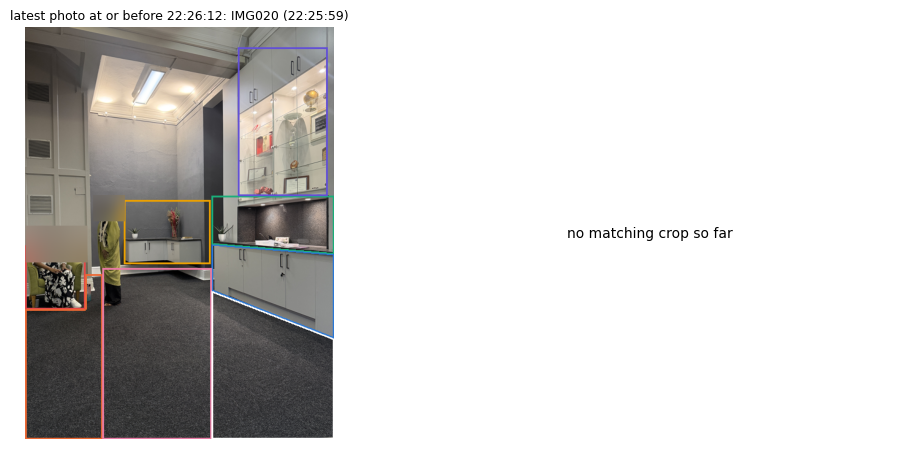

Placement log: visible | Counter


In [37]:
# E3: the same flow without widgets (reliable fallback, e.g. for a backup recording)
def pause_and_find(obj, t=None, reveal=True):
    t = t if t is not None else t_first + (t_last - t_first) * demo_rng.uniform()
    a = answer(history('S2', t), obj)
    print(f'Paused at {fmt(t)}.\n{a["text"]}')
    evidence_figure('S2', t, obj, a)
    if reveal:
        e = expected('S2', obj, t)
        print('Placement log:', e['gt_now'], '|', ZONE_NAMES.get(e['exp_zone'], 'never seen yet'))
    return a

_ = pause_and_find('Keys')

## On-device check (separate; not shown by this notebook)
Kaggle or Colab timing says nothing about a phone. To support the claim "runs offline on a phone", run a separate test and report it only once it has actually run:
1. Export the frozen encoder to a mobile format, for example `torch.onnx.export` → ONNX Runtime Mobile, or ExecuTorch / TFLite. Check that the CLS embeddings for 10 S1 crops match the Colab ones (cosine > 0.99).
2. On the phone, in airplane mode, time: one frame decode, 9 crop embeddings, and scoring against the cached registration embeddings. Repeat 20 times and report the median.
3. Speak one answer with the phone's offline TTS.
4. Report the phone model, the runtime used and the numbers. If any step fails, report that instead.